# One-Stage Anchor-Free Object Detection — YOLO11

## 1. Environment Setup

This notebook implements an anchor-free YOLO11 detector for the
VisDrone2019-VID dataset.

All experiments follow the shared training protocol to ensure
comparability with Faster R-CNN, RetinaNet, and RT-DETR.

In [ ]:
%pip install -q ultralytics==8.4.202 pycocotools

In [ ]:
from pathlib import Path
import zipfile
import hashlib
import yaml

import torch
import pandas as pd
import ultralytics

from google.colab import drive
from ultralytics import YOLO

# Reproducibility
SEED = 42
IMG_SIZE_CV = 960
IMG_SIZE_FULL = 1280
EPOCHS_CV = 4
EPOCHS_FULL = 8

CLASSES = [
    "person", "bicycle", "car", "van",
    "truck", "tricycle", "bus", "motor"
]

# GPU
assert torch.cuda.is_available(), "GPU is not available!"

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("GPU:", torch.cuda.get_device_name(0))

# Google Drive
drive.mount("/content/drive")

# Directories
SHARED_DIR = Path("/content/drive/MyDrive/hw2")
ZIP_PATH = SHARED_DIR / "data_prepared.zip"

PREP_DIR = Path("/content/hw2/data_prepared")
WORK_DIR = Path("/content/hw2/yolo_cv")

# Save our model results persistently
RESULTS_DIR = Path("/content/drive/MyDrive/hw2_yolo")

WORK_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

assert ZIP_PATH.exists(), f"Dataset not found: {ZIP_PATH}"

print("\nShared folder:", SHARED_DIR)
print("Results folder:", RESULTS_DIR)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.11.0+cu130
Ultralytics: 8.4.202
GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Shared folder: /content/drive/MyDrive/hw2
Results folder: /content/drive/MyDrive/hw2_yolo


## 2. Dataset Loading and Verification

We use the shared preprocessed dataset provided by the team.

The dataset contains 5,439 images and annotations for eight
object classes. Five sequence-level folds are used to prevent
data leakage between consecutive video frames.

In [ ]:
# Extract the dataset only if it is not already available
if not (PREP_DIR / "preprocess.yaml").exists():
    print("Extracting dataset...")

    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall("/content/hw2")
else:
    print("Dataset already extracted.")

assert (PREP_DIR / "preprocess.yaml").exists()

# Dataset statistics
n_images = len(list((PREP_DIR / "images").glob("*.jpg")))
n_coco = len(list((PREP_DIR / "coco").glob("*.json")))

print("\nDataset:", PREP_DIR)
print("Images:", n_images)
print("COCO files:", n_coco)

assert n_images == 5439, "Unexpected image count!"
assert n_coco == 10, "Unexpected number of COCO files!"

# Verify that local folds match the shared ZIP
with zipfile.ZipFile(ZIP_PATH) as z:
    for name in [
        "folds.csv",
        "fold0_train.txt",
        "fold0_val.txt"
    ]:
        matches = [
            p for p in z.namelist()
            if p.endswith("/" + name) or p == name
        ]

        assert len(matches) == 1

        shared_hash = hashlib.sha256(
            z.read(matches[0])
        ).hexdigest()

        local_hash = hashlib.sha256(
            (PREP_DIR / name).read_bytes()
        ).hexdigest()

        assert shared_hash == local_hash, (
            f"Dataset version mismatch: {name}"
        )

        print(f"{name}: MATCH")

print("\nDataset verification passed.")

Dataset already extracted.

Dataset: /content/hw2/data_prepared
Images: 5439
COCO files: 10
folds.csv: MATCH
fold0_train.txt: MATCH
fold0_val.txt: MATCH

Dataset verification passed.


## 3. Cross-Validation Configuration

We use five sequence-level folds shared across all detectors.

For cross-validation:
- Training: every 10th frame
- Validation: every available prepared frame (every 5th original frame)
- Image size: 960 pixels
- Training epochs: 4
- Random seed: 42

Fold configurations are generated using absolute paths to the
locally extracted dataset.

In [ ]:
def prepare_fold(fold):
    split_files = {}

    for split in ["train", "val"]:
        source = PREP_DIR / f"fold{fold}_{split}.txt"
        image_paths = []

        for line in source.read_text().splitlines():
            image = PREP_DIR / line.strip().removeprefix("./")

            frame = int(image.stem.rsplit("_", 1)[-1])

            # Subsample training only
            if split == "train" and (frame - 1) % 10 != 0:
                continue

            assert image.exists(), f"Missing image: {image}"
            image_paths.append(str(image.resolve()))

        output = WORK_DIR / f"fold{fold}_{split}_cv.txt"
        output.write_text("\n".join(image_paths) + "\n")

        split_files[split] = str(output)

        print(f"Fold {fold} {split}: {len(image_paths)} images")

    config = {
        "path": str(PREP_DIR),
        "train": split_files["train"],
        "val": split_files["val"],
        "nc": len(CLASSES),
        "names": CLASSES
    }

    yaml_path = WORK_DIR / f"fold{fold}_cv.yaml"

    with open(yaml_path, "w") as f:
        yaml.safe_dump(config, f, sort_keys=False)

    return yaml_path


# Prepare all 5 folds
FOLD_YAMLS = {}

for fold in range(5):
    FOLD_YAMLS[fold] = prepare_fold(fold)

# Verify Fold 0 annotations
yaml_path = FOLD_YAMLS[0]

with open(yaml_path) as f:
    fold0_config = yaml.safe_load(f)

sample_image = Path(
    Path(fold0_config["train"]).read_text().splitlines()[0]
)

sample_label = Path(
    str(sample_image).replace("/images/", "/labels/")
).with_suffix(".txt")

assert sample_image.exists()
assert sample_label.exists()

print("\nAll folds prepared successfully.")
print("Example image:", sample_image.name)
print("Labels verified:", sample_label.exists())

Fold 0 train: 2161 images
Fold 0 val: 1142 images
Fold 1 train: 2235 images
Fold 1 val: 992 images
Fold 2 train: 2088 images
Fold 2 val: 1285 images
Fold 3 train: 2191 images
Fold 3 val: 1080 images
Fold 4 train: 2261 images
Fold 4 val: 940 images

All folds prepared successfully.
Example image: uav0000013_00000_v_0000001.jpg
Labels verified: True


## 4. Smoke Test

A preliminary smoke test was completed successfully using
YOLO11n pretrained weights.

**Configuration**
- Training images: 64
- Validation images: 32
- Epochs: 1
- Image size: 960
- GPU: Tesla T4

**Results**
- Precision: 0.717
- Recall: 0.182
- mAP@50: 0.215
- mAP@50:95: 0.120

The test confirmed that image loading, YOLO annotations,
GPU training, validation, and checkpoint saving work correctly.

These results are diagnostic only and are not used for
the official cross-model comparison.

## 5. Baseline: YOLO11n

We fine-tune YOLO11n using pretrained weights and the shared
cross-validation protocol.

The baseline configuration remains fixed across all five folds.
The best checkpoint is selected using validation performance.

In [ ]:
import time
import torch
from ultralytics import YOLO

FOLD = 0
EXPERIMENT = "baseline"
RUN_NAME = f"yolo11n_{EXPERIMENT}_cv_fold{FOLD}"

RUN_DIR = RESULTS_DIR / RUN_NAME
BEST_PATH = RUN_DIR / "weights" / "best.pt"

TRAIN_MINUTES = None

assert torch.cuda.is_available(), "GPU is not available!"
assert FOLD_YAMLS[FOLD].exists(), "Fold configuration missing!"

if BEST_PATH.exists():
    print("Existing checkpoint found.")
    print("Skipping training:", BEST_PATH)

else:
    model = YOLO("yolo11n.pt")

    start = time.perf_counter()

    model.train(
        data=str(FOLD_YAMLS[FOLD]),
        imgsz=IMG_SIZE_CV,
        epochs=EPOCHS_CV,
        batch=4,
        device=0,
        workers=2,
        seed=SEED,
        deterministic=True,
        optimizer="AdamW",
        lr0=0.001,
        amp=True,
        cache=False,
        max_det=500,
        plots=False,
        project=str(RESULTS_DIR),
        name=RUN_NAME,
        exist_ok=True
    )

    TRAIN_MINUTES = (time.perf_counter() - start) / 60

assert BEST_PATH.exists(), "Training checkpoint missing!"

print("\nBaseline training completed.")
print("Checkpoint:", BEST_PATH)
print("Training minutes:", TRAIN_MINUTES)

New https://pypi.org/project/ultralytics/8.4.203 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hw2/yolo_cv/fold0_cv.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=4, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=500, mixup=0.0, mode=train, model=yolo11n.pt, mome

In [ ]:
import json
import contextlib
import io

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

GT_PATH = PREP_DIR / f"coco/fold{FOLD}_val.json"

# Load the validation ground truth
gt = COCO(str(GT_PATH))

# Map image filenames to COCO IDs
image_to_id = {
    Path(img["file_name"]).name: img["id"]
    for img in gt.dataset["images"]
}

with open(FOLD_YAMLS[FOLD]) as f:
    fold_config = yaml.safe_load(f)

val_file = Path(fold_config["val"])
val_images = val_file.read_text().splitlines()

assert len(val_images) == len(image_to_id)
assert {Path(p).name for p in val_images} == set(image_to_id)

# Inspect ignored-region categories
crowd_categories = sorted({
    ann["category_id"]
    for ann in gt.dataset["annotations"]
    if ann.get("iscrowd", 0) == 1
})

print("Ignored-region category IDs:", crowd_categories)

# Load the trained checkpoint
model = YOLO(str(BEST_PATH))

detections = []
processed = 0

start = time.perf_counter()

predictions = model.predict(
    source=str(val_file),
    imgsz=IMG_SIZE_CV,
    conf=0.01,
    iou=0.7,
    max_det=500,
    batch=4,
    device=0,
    stream=True,
    verbose=False,
    save=False
)

for result in predictions:
    image_name = Path(result.path).name
    image_id = image_to_id[image_name]

    boxes = result.boxes

    if boxes is not None and len(boxes):
        xyxy = boxes.xyxy.cpu().numpy()
        scores = boxes.conf.cpu().numpy()
        classes = boxes.cls.int().cpu().numpy()

        for box, score, cls in zip(xyxy, scores, classes):
            x1, y1, x2, y2 = map(float, box)

            detections.append({
                "image_id": int(image_id),
                "category_id": int(cls) + 1,
                "bbox": [
                    x1,
                    y1,
                    max(0.0, x2 - x1),
                    max(0.0, y2 - y1)
                ],
                "score": float(score)
            })

    processed += 1

inference_seconds = time.perf_counter() - start

assert processed == len(val_images), "Missing validation predictions!"

# Save raw predictions
DETS_PATH = (
    RESULTS_DIR /
    f"{EXPERIMENT}_cv_fold{FOLD}_val_dets.json"
)

with open(DETS_PATH, "w") as f:
    json.dump(detections, f)

print("Images evaluated:", processed)
print("Detections:", len(detections))

# Evaluate with pycocotools
if detections:
    with contextlib.redirect_stdout(io.StringIO()):
        evaluator = COCOeval(
            gt,
            gt.loadRes(detections),
            "bbox"
        )

        evaluator.params.maxDets = [1, 100, 500]
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()

    stats = evaluator.stats

    metrics = {
        "mAP": float(stats[0]),
        "AP50": float(stats[1]),
        "AP_small": float(stats[3]),
        "AP_medium": float(stats[4]),
        "AP_large": float(stats[5])
    }
else:
    metrics = {
        key: 0.0
        for key in [
            "mAP", "AP50", "AP_small",
            "AP_medium", "AP_large"
        ]
    }

metrics["FPS"] = processed / inference_seconds

print("\nOfficial COCO evaluation:")
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

loading annotations into memory...
Done (t=0.21s)
creating index...
index created!
Ignored-region category IDs: [1, 2, 3, 4, 5, 6, 7, 8]
Images evaluated: 1142
Detections: 230820

Official COCO evaluation:
mAP: 0.1679
AP50: 0.3264
AP_small: 0.0758
AP_medium: 0.1544
AP_large: 0.3816
FPS: 64.3209


In [ ]:
import pandas as pd

# Read training history
history_path = RUN_DIR / "results.csv"
history = pd.read_csv(history_path)
history.columns = history.columns.str.strip()

last_epoch = history.iloc[-1]

loss = sum(
    float(last_epoch[column])
    for column in [
        "train/box_loss",
        "train/cls_loss",
        "train/dfl_loss"
    ]
)

record = {
    "experiment": EXPERIMENT,
    "mode": "cv",
    "fold": FOLD,
    "epoch": int(last_epoch["epoch"]),
    "mAP": metrics["mAP"],
    "AP50": metrics["AP50"],
    "AP_small": metrics["AP_small"],
    "AP_medium": metrics["AP_medium"],
    "AP_large": metrics["AP_large"],
    "loss": loss,
    "minutes": TRAIN_MINUTES,
    "FPS": metrics["FPS"]
}

RESULTS_CSV = RESULTS_DIR / "results.csv"

if RESULTS_CSV.exists():
    df = pd.read_csv(RESULTS_CSV)

    previous = (
        (df["experiment"] == EXPERIMENT) &
        (df["mode"] == "cv") &
        (df["fold"] == FOLD)
    )

    if previous.any() and TRAIN_MINUTES is None:
        record["minutes"] = df.loc[previous, "minutes"].iloc[0]

    df = df.loc[~previous]
    df = pd.concat([df, pd.DataFrame([record])], ignore_index=True)
else:
    df = pd.DataFrame([record])

df = df.sort_values(["experiment", "mode", "fold"])
df.to_csv(RESULTS_CSV, index=False)

print("Results saved:", RESULTS_CSV)
display(df)

Results saved: /content/drive/MyDrive/hw2_yolo/results.csv


,experiment,mode,fold,epoch,mAP,AP50,AP_small,AP_medium,AP_large,loss,minutes,FPS
0,baseline,cv,0,4,0.167865,0.326382,0.075802,0.154421,0.38158,3.83641,8.661945,64.320948


In [ ]:
from pathlib import Path
import yaml
import zipfile
import hashlib

with open(FOLD_YAMLS[0]) as f:
    cfg = yaml.safe_load(f)

train_paths = Path(cfg["train"]).read_text().splitlines()
val_paths = Path(cfg["val"]).read_text().splitlines()

print("Current Fold 0:")
print("Train images:", len(train_paths))
print("Val images:", len(val_paths))

print("\nShared ZIP consistency:")

with zipfile.ZipFile(ZIP_PATH) as z:
    for name in ["folds.csv", "fold0_train.txt", "fold0_val.txt"]:
        matches = [
            p for p in z.namelist()
            if p.endswith("/" + name) or p == name
        ]

        assert len(matches) == 1

        zip_hash = hashlib.sha256(z.read(matches[0])).hexdigest()
        local_hash = hashlib.sha256(
            (PREP_DIR / name).read_bytes()
        ).hexdigest()

        print(
            name,
            "MATCH" if zip_hash == local_hash else "DIFFERENT"
        )

Current Fold 0:
Train images: 2161
Val images: 1142

Shared ZIP consistency:
folds.csv MATCH
fold0_train.txt MATCH
fold0_val.txt MATCH


In [ ]:
import time
import json
import io
import contextlib

import pandas as pd
from pathlib import Path
from ultralytics import YOLO
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval


def run_cv_fold(
    fold,
    experiment="baseline",
    scale=0.5,
    box_gain=7.5
):
    run_name = f"yolo11n_{experiment}_cv_fold{fold}"

    run_dir = RESULTS_DIR / run_name
    best_path = run_dir / "weights" / "best.pt"
    history_path = run_dir / "results.csv"
    dets_path = RESULTS_DIR / f"{experiment}_cv_fold{fold}_val_dets.json"
    results_path = RESULTS_DIR / "results.csv"

    print(f"\n{'=' * 55}")
    print(f"YOLO11n baseline — Fold {fold}")
    print(f"{'=' * 55}")

    training_minutes = None

    # 1. Train if a completed checkpoint is unavailable
    completed = False

    if best_path.exists() and history_path.exists():
        history = pd.read_csv(history_path)
        history.columns = history.columns.str.strip()
        completed = (
            len(history) >= EPOCHS_CV
            and int(history["epoch"].max()) >= EPOCHS_CV
        )

    if completed:
        print("Completed training found. Skipping training.")

    else:
        print("Starting training...")

        model = YOLO("yolo11n.pt")
        start = time.perf_counter()

        model.train(
            data=str(FOLD_YAMLS[fold]),
            imgsz=IMG_SIZE_CV,
            epochs=EPOCHS_CV,
            batch=4,
            device=0,
            workers=2,
            seed=SEED,
            deterministic=True,
            optimizer="AdamW",
            lr0=0.001,
            scale=scale,
            box=box_gain,
            amp=True,
            cache=False,
            max_det=500,
            plots=False,
            project=str(RESULTS_DIR),
            name=run_name,
            exist_ok=True
        )

        training_minutes = (
            time.perf_counter() - start
        ) / 60

    assert best_path.exists(), "Checkpoint missing!"

    # 2. Load validation annotations
    gt_path = PREP_DIR / f"coco/fold{fold}_val.json"
    gt = COCO(str(gt_path))

    image_to_id = {
        Path(img["file_name"]).name: img["id"]
        for img in gt.dataset["images"]
    }

    with open(FOLD_YAMLS[fold]) as f:
        fold_cfg = yaml.safe_load(f)

    val_file = Path(fold_cfg["val"])
    val_images = val_file.read_text().splitlines()

    assert len(val_images) == len(image_to_id)
    assert {Path(p).name for p in val_images} == set(image_to_id)

    # 3. Generate predictions if they have not been saved
    if dets_path.exists():
        print("Existing predictions found. Loading...")
        with open(dets_path) as f:
            detections = json.load(f)

        inference_seconds = None

    else:
        print("Generating validation predictions...")

        model = YOLO(str(best_path))
        detections = []

        start = time.perf_counter()

        predictions = model.predict(
            source=str(val_file),
            imgsz=IMG_SIZE_CV,
            conf=0.01,
            iou=0.7,
            max_det=500,
            batch=4,
            device=0,
            stream=True,
            verbose=False,
            save=False
        )

        processed = 0

        for result in predictions:
            image_name = Path(result.path).name
            image_id = image_to_id[image_name]

            boxes = result.boxes

            if boxes is not None and len(boxes):
                xyxy = boxes.xyxy.cpu().numpy()
                scores = boxes.conf.cpu().numpy()
                classes = boxes.cls.int().cpu().numpy()

                for box, score, cls in zip(xyxy, scores, classes):
                    x1, y1, x2, y2 = map(float, box)

                    detections.append({
                        "image_id": int(image_id),
                        "category_id": int(cls) + 1,
                        "bbox": [
                            x1, y1,
                            max(0.0, x2 - x1),
                            max(0.0, y2 - y1)
                        ],
                        "score": float(score)
                    })

            processed += 1

        inference_seconds = time.perf_counter() - start
        assert processed == len(val_images)

        with open(dets_path, "w") as f:
            json.dump(detections, f)

    # 4. Official COCO evaluation
    if detections:
        with contextlib.redirect_stdout(io.StringIO()):
            evaluator = COCOeval(
                gt,
                gt.loadRes(detections),
                "bbox"
            )

            evaluator.params.maxDets = [1, 100, 500]
            evaluator.evaluate()
            evaluator.accumulate()
            evaluator.summarize()

        stats = evaluator.stats

        metrics = {
            "mAP": float(stats[0]),
            "AP50": float(stats[1]),
            "AP_small": float(stats[3]),
            "AP_medium": float(stats[4]),
            "AP_large": float(stats[5])
        }
    else:
        metrics = {
            k: 0.0 for k in [
                "mAP", "AP50", "AP_small",
                "AP_medium", "AP_large"
            ]
        }

    # 5. Save experiment metrics
    history = pd.read_csv(history_path)
    history.columns = history.columns.str.strip()
    last_epoch = history.iloc[-1]

    loss = sum(
        float(last_epoch[c])
        for c in [
            "train/box_loss",
            "train/cls_loss",
            "train/dfl_loss"
        ]
    )

    existing = (
        pd.read_csv(results_path)
        if results_path.exists()
        else pd.DataFrame()
    )

    previous = pd.DataFrame()

    if not existing.empty:
        mask = (
            (existing["experiment"] == experiment) &
            (existing["mode"] == "cv") &
            (existing["fold"] == fold)
        )
        previous = existing.loc[mask]
        existing = existing.loc[~mask].copy()

    if training_minutes is None and not previous.empty:
        training_minutes = previous.iloc[0]["minutes"]

    fps = (
        len(val_images) / inference_seconds
        if inference_seconds
        else (
            previous.iloc[0]["FPS"]
            if not previous.empty
            else float("nan")
        )
    )

    record = {
        "experiment": experiment,
        "mode": "cv",
        "fold": fold,
        "epoch": int(last_epoch["epoch"]),
        **metrics,
        "loss": loss,
        "minutes": training_minutes,
        "FPS": fps
    }

    updated = pd.concat(
        [existing, pd.DataFrame([record])],
        ignore_index=True
    )

    updated = updated.sort_values(
        ["experiment", "mode", "fold"]
    )

    updated.to_csv(results_path, index=False)

    print(f"\nFold {fold} completed:")
    print(f"mAP: {metrics['mAP']:.4f}")
    print(f"AP50: {metrics['AP50']:.4f}")
    print(f"AP_small: {metrics['AP_small']:.4f}")
    print("Predictions:", dets_path)

    return record

In [ ]:
fold1_result = run_baseline_fold(1)


YOLO11n baseline — Fold 1
Starting training...
New https://pypi.org/project/ultralytics/8.4.203 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hw2/yolo_cv/fold1_cv.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=4, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=50

In [ ]:
for fold in [2, 3, 4]:
    run_baseline_fold(fold)

print("\nAll baseline folds completed!")

results = pd.read_csv(RESULTS_DIR / "results.csv")

display(
    results[
        (results["experiment"] == "baseline") &
        (results["mode"] == "cv")
    ].sort_values("fold")
)


YOLO11n baseline — Fold 2
Starting training...
New https://pypi.org/project/ultralytics/8.4.203 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hw2/yolo_cv/fold2_cv.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=4, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=50

,experiment,mode,fold,epoch,mAP,AP50,AP_small,AP_medium,AP_large,loss,minutes,FPS
0,baseline,cv,0,4,0.167865,0.326382,0.075802,0.154421,0.381580,3.83641,8.661945,64.320948
1,baseline,cv,1,4,0.166469,0.324998,0.048825,0.161257,0.377677,3.76888,8.010138,58.156219
2,baseline,cv,2,4,0.152063,0.310085,0.049829,0.176738,0.315114,3.79055,8.073589,62.482497
3,baseline,cv,3,4,0.126858,0.249610,0.031805,0.151521,0.245959,3.85131,8.049620,56.804708
4,baseline,cv,4,4,0.149704,0.281445,0.033159,0.124883,0.378303,3.85479,8.168277,55.823686


## 7. Out-of-Fold Evaluation

All validation predictions are combined into one dataset.
Image and annotation IDs are reassigned to avoid collisions
between folds. Metrics are calculated using pycocotools.

In [ ]:
import json
import time
from pathlib import Path

start = time.perf_counter()

merged_gt = {
    "info": {"description": "YOLO11n 5-fold OOF validation"},
    "licenses": [],
    "images": [],
    "annotations": [],
    "categories": [
        {"id": i + 1, "name": name}
        for i, name in enumerate(CLASSES)
    ]
}

merged_dets = []
seen_images = set()

next_img_id = 1
next_ann_id = 1

for fold in range(5):
    gt_path = PREP_DIR / f"coco/fold{fold}_val.json"
    det_path = RESULTS_DIR / f"baseline_cv_fold{fold}_val_dets.json"

    assert gt_path.exists(), f"Missing annotations: {gt_path}"
    assert det_path.exists(), f"Missing predictions: {det_path}"

    with open(gt_path) as f:
        fold_gt = json.load(f)

    with open(det_path) as f:
        fold_dets = json.load(f)

    # Check identical category definitions
    assert {
        c["id"]: c["name"] for c in fold_gt["categories"]
    } == {
        c["id"]: c["name"] for c in merged_gt["categories"]
    }

    id_map = {}

    for img in fold_gt["images"]:
        filename = img["file_name"]

        assert filename not in seen_images, (
            f"Image appears in multiple folds: {filename}"
        )
        seen_images.add(filename)

        id_map[img["id"]] = next_img_id

        new_img = img.copy()
        new_img["id"] = next_img_id

        merged_gt["images"].append(new_img)
        next_img_id += 1

    for ann in fold_gt["annotations"]:
        new_ann = ann.copy()
        new_ann["id"] = next_ann_id
        new_ann["image_id"] = id_map[ann["image_id"]]

        merged_gt["annotations"].append(new_ann)
        next_ann_id += 1

    for det in fold_dets:
        assert det["image_id"] in id_map

        new_det = det.copy()
        new_det["image_id"] = id_map[det["image_id"]]
        merged_dets.append(new_det)

    print(
        f"Fold {fold}: "
        f"{len(fold_gt['images'])} images, "
        f"{len(fold_dets)} detections"
    )

assert len(merged_gt["images"]) == 5439
assert len(seen_images) == 5439
assert len(merged_dets) > 0

print("\nOOF dataset prepared")
print("Images:", len(merged_gt["images"]))
print("Annotations:", len(merged_gt["annotations"]))
print("Predictions:", len(merged_dets))
print(f"Time: {time.perf_counter() - start:.1f}s")

Fold 0: 1142 images, 230820 detections
Fold 1: 992 images, 167932 detections
Fold 2: 1285 images, 222746 detections
Fold 3: 1080 images, 173793 detections
Fold 4: 940 images, 266708 detections

OOF dataset prepared
Images: 5439
Annotations: 355409
Predictions: 1061999
Time: 13.6s


In [ ]:
import io
import contextlib
import pandas as pd

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

start = time.perf_counter()

with contextlib.redirect_stdout(io.StringIO()):
    coco_gt = COCO()
    coco_gt.dataset = merged_gt
    coco_gt.createIndex()

    coco_dt = coco_gt.loadRes(merged_dets)

    evaluator = COCOeval(coco_gt, coco_dt, "bbox")
    evaluator.params.maxDets = [1, 100, 500]

    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

stats = evaluator.stats

oof_metrics = {
    "experiment": "baseline",
    "model": "YOLO11n",
    "mode": "cv_oof",
    "folds": 5,
    "images": len(merged_gt["images"]),
    "mAP": float(stats[0]),
    "AP50": float(stats[1]),
    "AP_small": float(stats[3]),
    "AP_medium": float(stats[4]),
    "AP_large": float(stats[5])
}

oof_path = RESULTS_DIR / "baseline_oof_metrics.json"

with open(oof_path, "w") as f:
    json.dump(oof_metrics, f, indent=2)

fold_results = pd.read_csv(RESULTS_DIR / "results.csv")

baseline = fold_results[
    (fold_results["experiment"] == "baseline") &
    (fold_results["mode"] == "cv")
].sort_values("fold")

assert len(baseline) == 5
assert set(baseline["fold"].astype(int)) == set(range(5))

print("YOLO11n BASELINE — OOF RESULTS")
print("=" * 45)

for key in ["mAP", "AP50", "AP_small", "AP_medium", "AP_large"]:
    print(f"{key:12}: {oof_metrics[key]:.4f}")

print("\nMean fold mAP:", round(baseline["mAP"].mean(), 4))
print("Fold mAP std:", round(baseline["mAP"].std(), 4))
print("Combined OOF mAP:", round(oof_metrics["mAP"], 4))

print("\nSaved:", oof_path)
print(f"Evaluation time: {time.perf_counter() - start:.1f}s")

YOLO11n BASELINE — OOF RESULTS
mAP         : 0.1470
AP50        : 0.2897
AP_small    : 0.0403
AP_medium   : 0.1455
AP_large    : 0.3144

Mean fold mAP: 0.1526
Fold mAP std: 0.0166
Combined OOF mAP: 0.147

Saved: /content/drive/MyDrive/hw2_yolo/baseline_oof_metrics.json
Evaluation time: 536.9s


## 8. Hyperparameter Tuning — Reduced Scale Augmentation

We investigate whether reducing the strength of random scaling
improves detection of small objects.

The baseline uses scale=0.50. This experiment changes only
scale to 0.15 while keeping the remaining training
configuration unchanged.

In [ ]:
import time
import json
import pandas as pd

from ultralytics import YOLO

FOLD = 0
EXPERIMENT = "scale015"

RUN_NAME = f"yolo11n_{EXPERIMENT}_cv_fold{FOLD}"
RUN_DIR = RESULTS_DIR / RUN_NAME

BEST_PATH = RUN_DIR / "weights" / "best.pt"
HISTORY_PATH = RUN_DIR / "results.csv"

if BEST_PATH.exists() and HISTORY_PATH.exists():
    history = pd.read_csv(HISTORY_PATH)
    history.columns = history.columns.str.strip()

    assert (
        len(history) >= EPOCHS_CV
        and int(history["epoch"].max()) >= EPOCHS_CV
    ), "Incomplete experiment found. Check training history."

    print("Completed checkpoint already exists.")
    print("Skipping training.")

else:
    print("Training YOLO11n with scale=0.15...")

    model = YOLO("yolo11n.pt")

    start = time.perf_counter()

    model.train(
        data=str(FOLD_YAMLS[FOLD]),
        imgsz=IMG_SIZE_CV,
        epochs=EPOCHS_CV,
        batch=4,
        device=0,
        workers=2,
        seed=SEED,
        deterministic=True,
        optimizer="AdamW",
        lr0=0.001,
        amp=True,
        cache=False,
        max_det=500,
        scale=0.15,
        plots=False,
        project=str(RESULTS_DIR),
        name=RUN_NAME,
        exist_ok=True
    )

    training_minutes = (time.perf_counter() - start) / 60

    with open(RUN_DIR / "training_time.json", "w") as f:
        json.dump(
            {"training_minutes": training_minutes},
            f,
            indent=2
        )

    print(f"Training time: {training_minutes:.2f} min")

assert BEST_PATH.exists(), "Checkpoint missing!"

print("\nExperiment:", EXPERIMENT)
print("Fold:", FOLD)
print("Best checkpoint:", BEST_PATH)

Training YOLO11n with scale=0.15...
New https://pypi.org/project/ultralytics/8.4.203 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hw2/yolo_cv/fold0_cv.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=4, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=500, mixup=0.0

In [ ]:
import time
import json
import io
import contextlib
import pandas as pd

from pathlib import Path
from ultralytics import YOLO
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

FOLD = 0
EXPERIMENT = "scale015"

RUN_DIR = RESULTS_DIR / f"yolo11n_{EXPERIMENT}_cv_fold{FOLD}"
BEST_PATH = RUN_DIR / "weights" / "best.pt"

GT_PATH = PREP_DIR / f"coco/fold{FOLD}_val.json"
DETS_PATH = RESULTS_DIR / f"{EXPERIMENT}_cv_fold{FOLD}_val_dets.json"
RESULTS_CSV = RESULTS_DIR / "results.csv"

assert BEST_PATH.exists(), "Trained model not found!"

# 1. Load ground truth
gt = COCO(str(GT_PATH))

image_to_id = {
    Path(img["file_name"]).name: img["id"]
    for img in gt.dataset["images"]
}

with open(FOLD_YAMLS[FOLD]) as f:
    fold_config = yaml.safe_load(f)

val_file = Path(fold_config["val"])
val_images = val_file.read_text().splitlines()

assert len(val_images) == len(image_to_id)
assert {Path(p).name for p in val_images} == set(image_to_id)

# 2. Generate predictions
inference_seconds = None

if DETS_PATH.exists():
    print("Loading existing predictions...")

    with open(DETS_PATH) as f:
        detections = json.load(f)

else:
    print("Generating predictions...")

    model = YOLO(str(BEST_PATH))
    detections = []

    start = time.perf_counter()

    predictions = model.predict(
        source=str(val_file),
        imgsz=IMG_SIZE_CV,
        conf=0.01,
        iou=0.7,
        max_det=500,
        batch=4,
        device=0,
        stream=True,
        verbose=False,
        save=False
    )

    processed = 0

    for result in predictions:
        image_name = Path(result.path).name
        image_id = image_to_id[image_name]

        boxes = result.boxes

        if boxes is not None and len(boxes):
            xyxy = boxes.xyxy.cpu().numpy()
            scores = boxes.conf.cpu().numpy()
            classes = boxes.cls.int().cpu().numpy()

            for box, score, cls in zip(xyxy, scores, classes):
                x1, y1, x2, y2 = map(float, box)

                detections.append({
                    "image_id": int(image_id),
                    "category_id": int(cls) + 1,
                    "bbox": [
                        x1,
                        y1,
                        max(0.0, x2 - x1),
                        max(0.0, y2 - y1)
                    ],
                    "score": float(score)
                })

        processed += 1

    inference_seconds = time.perf_counter() - start

    assert processed == len(val_images)

    with open(DETS_PATH, "w") as f:
        json.dump(detections, f)

print("Detections:", len(detections))

# 3. Official COCO evaluation
start = time.perf_counter()

with contextlib.redirect_stdout(io.StringIO()):
    evaluator = COCOeval(
        gt,
        gt.loadRes(detections),
        "bbox"
    )

    evaluator.params.maxDets = [1, 100, 500]
    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

stats = evaluator.stats

metrics = {
    "mAP": float(stats[0]),
    "AP50": float(stats[1]),
    "AP_small": float(stats[3]),
    "AP_medium": float(stats[4]),
    "AP_large": float(stats[5])
}

evaluation_seconds = time.perf_counter() - start

# 4. Read training history
history = pd.read_csv(RUN_DIR / "results.csv")
history.columns = history.columns.str.strip()

last_epoch = history.iloc[-1]

loss = sum(
    float(last_epoch[col])
    for col in [
        "train/box_loss",
        "train/cls_loss",
        "train/dfl_loss"
    ]
)

with open(RUN_DIR / "training_time.json") as f:
    training_minutes = json.load(f)["training_minutes"]

# 5. Save metrics
df = pd.read_csv(RESULTS_CSV)

mask = (
    (df["experiment"] == EXPERIMENT) &
    (df["mode"] == "cv") &
    (df["fold"] == FOLD)
)

previous = df.loc[mask]
df = df.loc[~mask].copy()

fps = (
    len(val_images) / inference_seconds
    if inference_seconds is not None
    else (
        float(previous.iloc[0]["FPS"])
        if not previous.empty
        else float("nan")
    )
)

record = {
    "experiment": EXPERIMENT,
    "mode": "cv",
    "fold": FOLD,
    "epoch": int(last_epoch["epoch"]),
    **metrics,
    "loss": loss,
    "minutes": training_minutes,
    "FPS": fps
}

df = pd.concat(
    [df, pd.DataFrame([record])],
    ignore_index=True
)

df = df.sort_values(["experiment", "mode", "fold"])
df.to_csv(RESULTS_CSV, index=False)

# 6. Compare with baseline
baseline = df[
    (df["experiment"] == "baseline") &
    (df["mode"] == "cv") &
    (df["fold"] == FOLD)
].iloc[0]

print("\nEXPERIMENT 1 — FOLD 0 COMPARISON")
print("=" * 55)

for metric in [
    "mAP", "AP50", "AP_small",
    "AP_medium", "AP_large"
]:
    before = float(baseline[metric])
    after = metrics[metric]

    print(
        f"{metric:12} "
        f"Baseline: {before:.4f} | "
        f"Tuned: {after:.4f} | "
        f"Delta: {after-before:+.4f}"
    )

print(f"\nEvaluation time: {evaluation_seconds:.1f}s")
print("Saved predictions:", DETS_PATH)
print("Saved metrics:", RESULTS_CSV)

loading annotations into memory...
Done (t=0.93s)
creating index...
index created!
Generating predictions...
Detections: 197222

EXPERIMENT 1 — FOLD 0 COMPARISON
mAP          Baseline: 0.1679 | Tuned: 0.1649 | Delta: -0.0030
AP50         Baseline: 0.3264 | Tuned: 0.3201 | Delta: -0.0063
AP_small     Baseline: 0.0758 | Tuned: 0.0733 | Delta: -0.0025
AP_medium    Baseline: 0.1544 | Tuned: 0.1608 | Delta: +0.0064
AP_large     Baseline: 0.3816 | Tuned: 0.3234 | Delta: -0.0582

Evaluation time: 92.0s
Saved predictions: /content/drive/MyDrive/hw2_yolo/scale015_cv_fold0_val_dets.json
Saved metrics: /content/drive/MyDrive/hw2_yolo/results.csv


In [ ]:
fold1_scale_result = run_cv_fold(
    fold=1,
    experiment="scale015",
    scale=0.15
)


YOLO11n baseline — Fold 1
Starting training...
New https://pypi.org/project/ultralytics/8.4.203 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hw2/yolo_cv/fold1_cv.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=4, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=50

In [ ]:
import pandas as pd

df = pd.read_csv(RESULTS_DIR / "results.csv")

comparison = df[
    (df["fold"] == 1) &
    (df["mode"] == "cv") &
    (df["experiment"].isin(["baseline", "scale015"]))
][
    ["experiment", "mAP", "AP50", "AP_small",
     "AP_medium", "AP_large"]
]

display(comparison)

,experiment,mAP,AP50,AP_small,AP_medium,AP_large
1,baseline,0.166469,0.324998,0.048825,0.161257,0.377677
6,scale015,0.167755,0.326521,0.055406,0.165527,0.367412


In [ ]:
for fold in [2, 3, 4]:
    run_cv_fold(fold, experiment="scale015", scale=0.15)


YOLO11n baseline — Fold 2
Starting training...
New https://pypi.org/project/ultralytics/8.4.203 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hw2/yolo_cv/fold2_cv.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=4, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=50

In [ ]:
import pandas as pd

df = pd.read_csv(RESULTS_DIR / "results.csv")

display(
    df[
        (df["experiment"].isin(["baseline", "scale015"])) &
        (df["mode"] == "cv")
    ][
        ["experiment", "fold", "mAP", "AP50", "AP_small", "AP_medium", "AP_large"]
    ].sort_values(["experiment", "fold"])
)

,experiment,fold,mAP,AP50,AP_small,AP_medium,AP_large
0,baseline,0,0.167865,0.326382,0.075802,0.154421,0.381580
1,baseline,1,0.166469,0.324998,0.048825,0.161257,0.377677
2,baseline,2,0.152063,0.310085,0.049829,0.176738,0.315114
3,baseline,3,0.126858,0.249610,0.031805,0.151521,0.245959
4,baseline,4,0.149704,0.281445,0.033159,0.124883,0.378303
5,scale015,0,0.164886,0.320077,0.073258,0.160834,0.323428
6,scale015,1,0.167755,0.326521,0.055406,0.165527,0.367412
7,scale015,2,0.146362,0.307066,0.046684,0.155267,0.300171
8,scale015,3,0.139044,0.274199,0.040268,0.159212,0.265435
9,scale015,4,0.146349,0.282238,0.036237,0.124558,0.349562


## 8.5. Combined OOF Evaluation — Scale 0.15

We combine out-of-fold predictions from all five validation
folds for the reduced-scale augmentation experiment.

The evaluation follows the same COCO protocol as the baseline:
confidence threshold 0.01 and maxDets = [1, 100, 500].

In [ ]:
import json
import time
from pathlib import Path

EXPERIMENT = "scale015"

start = time.perf_counter()

merged_gt = {
    "info": {"description": "Scale 0.15 OOF evaluation"},
    "licenses": [],
    "images": [],
    "annotations": [],
    "categories": []
}

merged_dets = []
seen_images = set()

next_img_id = 1
next_ann_id = 1

for fold in range(5):
    gt_path = PREP_DIR / f"coco/fold{fold}_val.json"
    det_path = RESULTS_DIR / f"{EXPERIMENT}_cv_fold{fold}_val_dets.json"

    assert gt_path.exists(), f"Missing: {gt_path}"
    assert det_path.exists(), f"Missing: {det_path}"

    with open(gt_path) as f:
        fold_gt = json.load(f)

    with open(det_path) as f:
        fold_dets = json.load(f)

    if fold == 0:
        merged_gt["categories"] = fold_gt["categories"]
    else:
        assert fold_gt["categories"] == merged_gt["categories"]

    id_map = {}

    for img in fold_gt["images"]:
        filename = img["file_name"]

        assert filename not in seen_images
        seen_images.add(filename)

        id_map[img["id"]] = next_img_id

        new_img = img.copy()
        new_img["id"] = next_img_id

        merged_gt["images"].append(new_img)
        next_img_id += 1

    for ann in fold_gt["annotations"]:
        new_ann = ann.copy()
        new_ann["id"] = next_ann_id
        new_ann["image_id"] = id_map[ann["image_id"]]

        merged_gt["annotations"].append(new_ann)
        next_ann_id += 1

    for det in fold_dets:
        assert det["image_id"] in id_map

        new_det = det.copy()
        new_det["image_id"] = id_map[det["image_id"]]
        merged_dets.append(new_det)

    print(
        f"Fold {fold}: "
        f"{len(fold_gt['images'])} images, "
        f"{len(fold_dets)} predictions"
    )

assert len(merged_gt["images"]) == 5439
assert len(seen_images) == 5439
assert len(merged_dets) > 0

print("\nOOF dataset prepared:")
print("Images:", len(merged_gt["images"]))
print("Annotations:", len(merged_gt["annotations"]))
print("Predictions:", len(merged_dets))
print(f"Time: {time.perf_counter() - start:.1f}s")

Fold 0: 1142 images, 197222 predictions
Fold 1: 992 images, 161567 predictions
Fold 2: 1285 images, 227391 predictions
Fold 3: 1080 images, 210128 predictions
Fold 4: 940 images, 247572 predictions

OOF dataset prepared:
Images: 5439
Annotations: 355409
Predictions: 1043880
Time: 11.4s


In [ ]:
import io
import json
import time
import contextlib
import pandas as pd

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

start = time.perf_counter()

print("Starting combined OOF evaluation...")

with contextlib.redirect_stdout(io.StringIO()):
    coco_gt = COCO()
    coco_gt.dataset = merged_gt
    coco_gt.createIndex()

    coco_dt = coco_gt.loadRes(merged_dets)

    evaluator = COCOeval(coco_gt, coco_dt, "bbox")
    evaluator.params.maxDets = [1, 100, 500]

    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

stats = evaluator.stats

oof_metrics = {
    "experiment": "scale015",
    "model": "YOLO11n",
    "mode": "cv_oof",
    "folds": 5,
    "images": len(merged_gt["images"]),
    "mAP": float(stats[0]),
    "AP50": float(stats[1]),
    "AP_small": float(stats[3]),
    "AP_medium": float(stats[4]),
    "AP_large": float(stats[5])
}

# Save without overwriting baseline
oof_path = RESULTS_DIR / "scale015_oof_metrics.json"

with open(oof_path, "w") as f:
    json.dump(oof_metrics, f, indent=2)

# Load previously calculated baseline
baseline_path = RESULTS_DIR / "baseline_oof_metrics.json"

assert baseline_path.exists(), "Baseline OOF metrics missing!"

with open(baseline_path) as f:
    baseline = json.load(f)

# Compare both experiments
rows = []

for metric in [
    "mAP", "AP50", "AP_small",
    "AP_medium", "AP_large"
]:
    before = float(baseline[metric])
    after = float(oof_metrics[metric])

    rows.append({
        "Metric": metric,
        "Baseline": before,
        "Scale 0.15": after,
        "Delta": after - before
    })

comparison = pd.DataFrame(rows)

print("\nCOMBINED OOF COMPARISON")
print("=" * 50)

display(
    comparison.style.format({
        "Baseline": "{:.4f}",
        "Scale 0.15": "{:.4f}",
        "Delta": "{:+.4f}"
    })
)

print(f"\nEvaluation time: {(time.perf_counter() - start)/60:.2f} min")
print("Saved:", oof_path)

Starting combined OOF evaluation...

COMBINED OOF COMPARISON


,Metric,Baseline,Scale 0.15,Delta
0,mAP,0.1470,0.1484,+0.0014
1,AP50,0.2897,0.2946,+0.0049
2,AP_small,0.0403,0.0445,+0.0043
3,AP_medium,0.1455,0.1454,-0.0001
4,AP_large,0.3144,0.3189,+0.0045



Evaluation time: 8.26 min
Saved: /content/drive/MyDrive/hw2_yolo/scale015_oof_metrics.json


In [ ]:
import time
import json
import pandas as pd

from ultralytics import YOLO

FOLD = 0
EXPERIMENT = "box10"

RUN_NAME = f"yolo11n_{EXPERIMENT}_cv_fold{FOLD}"
RUN_DIR = RESULTS_DIR / RUN_NAME

BEST_PATH = RUN_DIR / "weights" / "best.pt"
HISTORY_PATH = RUN_DIR / "results.csv"

if BEST_PATH.exists() and HISTORY_PATH.exists():
    history = pd.read_csv(HISTORY_PATH)
    history.columns = history.columns.str.strip()

    assert (
        len(history) >= EPOCHS_CV
        and int(history["epoch"].max()) >= EPOCHS_CV
    ), "Incomplete checkpoint. Check training history."

    print("Completed checkpoint found. Skipping training.")

else:
    print("Training YOLO11n with box loss gain = 10.0")

    model = YOLO("yolo11n.pt")

    start = time.perf_counter()

    model.train(
        data=str(FOLD_YAMLS[FOLD]),
        imgsz=IMG_SIZE_CV,
        epochs=EPOCHS_CV,
        batch=4,
        device=0,
        workers=2,
        seed=SEED,
        deterministic=True,
        optimizer="AdamW",
        lr0=0.001,
        scale=0.5,
        box=10.0,
        cls=0.5,
        dfl=1.5,
        amp=True,
        cache=False,
        max_det=500,
        plots=False,
        project=str(RESULTS_DIR),
        name=RUN_NAME,
        exist_ok=True
    )

    training_minutes = (
        time.perf_counter() - start
    ) / 60

    with open(RUN_DIR / "training_time.json", "w") as f:
        json.dump(
            {"training_minutes": training_minutes},
            f,
            indent=2
        )

    print(f"Training time: {training_minutes:.2f} min")

assert BEST_PATH.exists(), "Checkpoint missing!"

print("\nExperiment:", EXPERIMENT)
print("Fold:", FOLD)
print("Best checkpoint:", BEST_PATH)

Training YOLO11n with box loss gain = 10.0
New https://pypi.org/project/ultralytics/8.4.203 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=10.0, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hw2/yolo_cv/fold0_cv.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=4, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=500, m

In [ ]:
import json
import pandas as pd

FOLD = 0
EXPERIMENT = "box10"

run_dir = RESULTS_DIR / "yolo11n_box10_cv_fold0"
best_path = run_dir / "weights" / "best.pt"

assert best_path.exists(), "Checkpoint not found!"

history = pd.read_csv(run_dir / "results.csv")
history.columns = history.columns.str.strip()

assert (
    len(history) >= EPOCHS_CV
    and int(history["epoch"].max()) >= EPOCHS_CV
), "Training is not complete!"

# Existing checkpoint will be used — no retraining
box10_result = run_cv_fold(
    fold=0,
    experiment="box10",
    scale=0.5
)

# Restore the actual training time
with open(run_dir / "training_time.json") as f:
    training_minutes = json.load(f)["training_minutes"]

results_path = RESULTS_DIR / "results.csv"
df = pd.read_csv(results_path)

mask = (
    (df["experiment"] == "box10") &
    (df["mode"] == "cv") &
    (df["fold"] == 0)
)

df.loc[mask, "minutes"] = training_minutes
df.to_csv(results_path, index=False)

# Compare baseline, Experiment 1 and Experiment 2
comparison = df[
    (df["fold"] == 0) &
    (df["mode"] == "cv") &
    (df["experiment"].isin([
        "baseline", "scale015", "box10"
    ]))
][[
    "experiment", "mAP", "AP50",
    "AP_small", "AP_medium", "AP_large"
]]

display(comparison.sort_values("experiment"))


YOLO11n baseline — Fold 0
Completed training found. Skipping training.
loading annotations into memory...
Done (t=0.19s)
creating index...
index created!
Generating validation predictions...


/tmp/ipykernel_2952/3903748323.py:243: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  updated = pd.concat(



Fold 0 completed:
mAP: 0.1718
AP50: 0.3245
AP_small: 0.0805
Predictions: /content/drive/MyDrive/hw2_yolo/box10_cv_fold0_val_dets.json


,experiment,mAP,AP50,AP_small,AP_medium,AP_large
0,baseline,0.167865,0.326382,0.075802,0.154421,0.381580
5,box10,0.171833,0.324461,0.080547,0.163563,0.386423
6,scale015,0.164886,0.320077,0.073258,0.160834,0.323428


In [ ]:
fold1_box10_result = run_cv_fold(
    fold=1,
    experiment="box10",
    scale=0.5,
    box_gain=10.0
)


YOLO11n baseline — Fold 1
Starting training...
New https://pypi.org/project/ultralytics/8.4.203 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=10.0, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hw2/yolo_cv/fold1_cv.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=4, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=5

In [ ]:
import pandas as pd

df = pd.read_csv(RESULTS_DIR / "results.csv")

comparison = df[
    (df["fold"] == 1) &
    (df["mode"] == "cv") &
    (df["experiment"].isin(
        ["baseline", "scale015", "box10"]
    ))
][
    ["experiment", "mAP", "AP50",
     "AP_small", "AP_medium", "AP_large"]
]

display(comparison.sort_values("experiment"))

,experiment,mAP,AP50,AP_small,AP_medium,AP_large
1,baseline,0.166469,0.324998,0.048825,0.161257,0.377677
6,box10,0.166373,0.323024,0.069009,0.163987,0.379414
8,scale015,0.167755,0.326521,0.055406,0.165527,0.367412


In [ ]:
for fold in [2, 3, 4]:
    run_cv_fold(
        fold=fold,
        experiment="box10",
        scale=0.5,
        box_gain=10.0
    )


YOLO11n baseline — Fold 2
Starting training...
New https://pypi.org/project/ultralytics/8.4.203 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=10.0, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hw2/yolo_cv/fold2_cv.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=4, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=5

In [ ]:
import pandas as pd

df = pd.read_csv(RESULTS_DIR / "results.csv")

comparison = df[
    (df["experiment"].isin(["baseline", "scale015", "box10"])) &
    (df["mode"] == "cv")
][
    ["experiment", "fold", "mAP", "AP50",
     "AP_small", "AP_medium", "AP_large"]
].sort_values(["experiment", "fold"])

display(comparison)

,experiment,fold,mAP,AP50,AP_small,AP_medium,AP_large
0,baseline,0,0.167865,0.326382,0.075802,0.154421,0.381580
1,baseline,1,0.166469,0.324998,0.048825,0.161257,0.377677
2,baseline,2,0.152063,0.310085,0.049829,0.176738,0.315114
3,baseline,3,0.126858,0.249610,0.031805,0.151521,0.245959
4,baseline,4,0.149704,0.281445,0.033159,0.124883,0.378303
5,box10,0,0.171833,0.324461,0.080547,0.163563,0.386423
6,box10,1,0.166373,0.323024,0.069009,0.163987,0.379414
7,box10,2,0.149866,0.306272,0.050865,0.176629,0.287631
8,box10,3,0.122203,0.246873,0.038195,0.150209,0.227553
9,box10,4,0.143559,0.279533,0.034368,0.125876,0.338374


In [ ]:
import json
import time
from pathlib import Path

EXPERIMENT = "box10"

start = time.perf_counter()

merged_gt = {
    "info": {"description": "Box 10 OOF evaluation"},
    "licenses": [],
    "images": [],
    "annotations": [],
    "categories": []
}

merged_dets = []
seen_images = set()

next_img_id = 1
next_ann_id = 1

for fold in range(5):
    gt_path = PREP_DIR / f"coco/fold{fold}_val.json"
    det_path = RESULTS_DIR / f"{EXPERIMENT}_cv_fold{fold}_val_dets.json"

    assert gt_path.exists(), f"Missing: {gt_path}"
    assert det_path.exists(), f"Missing: {det_path}"

    with open(gt_path) as f:
        fold_gt = json.load(f)

    with open(det_path) as f:
        fold_dets = json.load(f)

    if fold == 0:
        merged_gt["categories"] = fold_gt["categories"]
    else:
        assert {
            c["id"]: c["name"] for c in fold_gt["categories"]
        } == {
            c["id"]: c["name"] for c in merged_gt["categories"]
        }

    id_map = {}

    for img in fold_gt["images"]:
        filename = img["file_name"]

        assert filename not in seen_images, (
            f"Duplicate image: {filename}"
        )
        seen_images.add(filename)

        id_map[img["id"]] = next_img_id

        new_img = img.copy()
        new_img["id"] = next_img_id

        merged_gt["images"].append(new_img)
        next_img_id += 1

    for ann in fold_gt["annotations"]:
        new_ann = ann.copy()
        new_ann["id"] = next_ann_id
        new_ann["image_id"] = id_map[ann["image_id"]]

        merged_gt["annotations"].append(new_ann)
        next_ann_id += 1

    for det in fold_dets:
        assert det["image_id"] in id_map

        new_det = det.copy()
        new_det["image_id"] = id_map[det["image_id"]]

        merged_dets.append(new_det)

    print(
        f"Fold {fold}: "
        f"{len(fold_gt['images'])} images, "
        f"{len(fold_dets)} predictions"
    )

assert len(merged_gt["images"]) == 5439
assert len(seen_images) == 5439
assert len(merged_gt["annotations"]) == 355409
assert len(merged_dets) > 0

print("\nOOF dataset prepared:")
print("Images:", len(merged_gt["images"]))
print("Annotations:", len(merged_gt["annotations"]))
print("Predictions:", len(merged_dets))
print(f"Time: {time.perf_counter() - start:.1f}s")

NameError: name 'PREP_DIR' is not defined

In [ ]:
import io
import json
import time
import contextlib
import pandas as pd

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

start = time.perf_counter()

print("Starting box10 combined OOF evaluation...")

with contextlib.redirect_stdout(io.StringIO()):
    coco_gt = COCO()
    coco_gt.dataset = merged_gt
    coco_gt.createIndex()

    coco_dt = coco_gt.loadRes(merged_dets)

    evaluator = COCOeval(coco_gt, coco_dt, "bbox")
    evaluator.params.maxDets = [1, 100, 500]

    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

stats = evaluator.stats

box10_oof = {
    "experiment": "box10",
    "model": "YOLO11n",
    "mode": "cv_oof",
    "folds": 5,
    "images": len(merged_gt["images"]),
    "mAP": float(stats[0]),
    "AP50": float(stats[1]),
    "AP_small": float(stats[3]),
    "AP_medium": float(stats[4]),
    "AP_large": float(stats[5])
}

# Save box10 metrics
box10_path = RESULTS_DIR / "box10_oof_metrics.json"

with open(box10_path, "w") as f:
    json.dump(box10_oof, f, indent=2)

# Load results from previous experiments
with open(RESULTS_DIR / "baseline_oof_metrics.json") as f:
    baseline_oof = json.load(f)

with open(RESULTS_DIR / "scale015_oof_metrics.json") as f:
    scale015_oof = json.load(f)

# Compare all three
metric_names = [
    "mAP", "AP50", "AP_small",
    "AP_medium", "AP_large"
]

comparison = pd.DataFrame({
    "Metric": metric_names,
    "Baseline": [baseline_oof[k] for k in metric_names],
    "Scale 0.15": [scale015_oof[k] for k in metric_names],
    "Box 10": [box10_oof[k] for k in metric_names]
})

comparison["Δ Scale vs Base"] = (
    comparison["Scale 0.15"] - comparison["Baseline"]
)

comparison["Δ Box vs Base"] = (
    comparison["Box 10"] - comparison["Baseline"]
)

print("\nFINAL YOLO11n CROSS-VALIDATION COMPARISON")
print("=" * 55)

display(
    comparison.style.format({
        "Baseline": "{:.4f}",
        "Scale 0.15": "{:.4f}",
        "Box 10": "{:.4f}",
        "Δ Scale vs Base": "{:+.4f}",
        "Δ Box vs Base": "{:+.4f}"
    })
)

# Save comparison
comparison.to_csv(
    RESULTS_DIR / "yolo_cv_experiments_comparison.csv",
    index=False
)

print(
    f"\nEvaluation time: "
    f"{(time.perf_counter() - start) / 60:.2f} min"
)

print("Saved:", box10_path)
print(
    "Comparison saved:",
    RESULTS_DIR / "yolo_cv_experiments_comparison.csv"
)

Starting box10 combined OOF evaluation...


NameError: name 'merged_gt' is not defined

In [ ]:
%pip install -q pycocotools

In [ ]:
from google.colab import drive
from pathlib import Path
import zipfile
import shutil
import json

drive.mount("/content/drive")

RESULTS_DIR = Path("/content/drive/MyDrive/hw2_yolo")
ZIP_PATH = Path("/content/drive/MyDrive/hw2/data_prepared.zip")
PREP_DIR = Path("/content/hw2/data_prepared")

(PREP_DIR / "coco").mkdir(parents=True, exist_ok=True)

assert ZIP_PATH.exists(), "Shared dataset ZIP not found!"
assert RESULTS_DIR.exists(), "YOLO results folder not found!"

# Restore only the COCO validation annotations
with zipfile.ZipFile(ZIP_PATH) as z:
    members = z.namelist()

    for fold in range(5):
        filename = f"coco/fold{fold}_val.json"

        matches = [
            member for member in members
            if member.endswith(filename)
        ]

        assert len(matches) == 1, (
            f"Expected one matching file: {filename}"
        )

        target = PREP_DIR / filename

        if not target.exists():
            with z.open(matches[0]) as src:
                with open(target, "wb") as dst:
                    shutil.copyfileobj(src, dst)

        print(f"Fold {fold} annotations: OK")

# Verify predictions are still saved
for fold in range(5):
    path = RESULTS_DIR / f"box10_cv_fold{fold}_val_dets.json"
    assert path.exists(), f"Missing predictions: {path}"
    print(f"Fold {fold} predictions: OK")

# Check whether OOF evaluation was already completed
oof_path = RESULTS_DIR / "box10_oof_metrics.json"

if oof_path.exists():
    print("\nExisting Box10 OOF results:")
    with open(oof_path) as f:
        print(json.dumps(json.load(f), indent=2))
else:
    print("\nReady to run Box10 OOF evaluation.")

print("\nRecovery completed successfully.")

Mounted at /content/drive
Fold 0 annotations: OK
Fold 1 annotations: OK
Fold 2 annotations: OK
Fold 3 annotations: OK
Fold 4 annotations: OK
Fold 0 predictions: OK
Fold 1 predictions: OK
Fold 2 predictions: OK
Fold 3 predictions: OK
Fold 4 predictions: OK

Ready to run Box10 OOF evaluation.

Recovery completed successfully.


In [ ]:
from pathlib import Path
from google.colab import drive
import zipfile
import shutil

# Mount Google Drive if necessary
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

ZIP_PATH = Path("/content/drive/MyDrive/hw2/data_prepared.zip")
PREP_DIR = Path("/content/hw2/data_prepared")
RESULTS_DIR = Path("/content/drive/MyDrive/hw2_yolo")

assert ZIP_PATH.exists(), f"ZIP not found: {ZIP_PATH}"
assert RESULTS_DIR.exists(), "YOLO results directory missing!"

(PREP_DIR / "coco").mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for fold in range(5):
        filename = f"coco/fold{fold}_val.json"

        matches = [
            name for name in z.namelist()
            if name.endswith(filename)
        ]

        assert len(matches) == 1, (
            f"Expected exactly one match for {filename}"
        )

        output_path = PREP_DIR / filename

        with z.open(matches[0]) as source:
            with open(output_path, "wb") as target:
                shutil.copyfileobj(source, target)

        print(f"Fold {fold} annotations restored: OK")

# Check prediction files
for fold in range(5):
    prediction_path = (
        RESULTS_DIR / f"box10_cv_fold{fold}_val_dets.json"
    )

    assert prediction_path.exists(), (
        f"Missing prediction file: {prediction_path}"
    )

    print(f"Fold {fold} predictions: OK")

print("\nAll files restored. Ready for OOF evaluation!")

Mounted at /content/drive
Fold 0 annotations restored: OK
Fold 1 annotations restored: OK
Fold 2 annotations restored: OK
Fold 3 annotations restored: OK
Fold 4 annotations restored: OK
Fold 0 predictions: OK
Fold 1 predictions: OK
Fold 2 predictions: OK
Fold 3 predictions: OK
Fold 4 predictions: OK

All files restored. Ready for OOF evaluation!


In [ ]:
import json
import time
from pathlib import Path

# Experiment configuration
EXPERIMENT = "box10"

RESULTS_DIR = Path("/content/drive/MyDrive/hw2_yolo")
PREP_DIR = Path("/content/hw2/data_prepared")

start = time.perf_counter()

# Initialize combined COCO dataset
merged_gt = {
    "info": {"description": "YOLO11n Box10 5-fold OOF"},
    "licenses": [],
    "images": [],
    "annotations": [],
    "categories": []
}

merged_dets = []
seen_images = set()

next_img_id = 1
next_ann_id = 1

# Merge all 5 folds
for fold in range(5):

    gt_path = PREP_DIR / f"coco/fold{fold}_val.json"
    det_path = RESULTS_DIR / f"{EXPERIMENT}_cv_fold{fold}_val_dets.json"

    assert gt_path.exists(), f"Missing annotations: {gt_path}"
    assert det_path.exists(), f"Missing predictions: {det_path}"

    with open(gt_path, "r") as f:
        fold_gt = json.load(f)

    with open(det_path, "r") as f:
        fold_dets = json.load(f)

    # Verify consistent categories
    if fold == 0:
        merged_gt["categories"] = fold_gt["categories"]
    else:
        assert {
            c["id"]: c["name"] for c in fold_gt["categories"]
        } == {
            c["id"]: c["name"] for c in merged_gt["categories"]
        }, f"Category mismatch in Fold {fold}"

    id_map = {}

    # Merge images with unique IDs
    for img in fold_gt["images"]:
        filename = img["file_name"]

        assert filename not in seen_images, (
            f"Duplicate image across folds: {filename}"
        )

        seen_images.add(filename)
        id_map[img["id"]] = next_img_id

        new_img = img.copy()
        new_img["id"] = next_img_id

        merged_gt["images"].append(new_img)
        next_img_id += 1

    # Merge ground-truth annotations
    for ann in fold_gt["annotations"]:
        new_ann = ann.copy()
        new_ann["id"] = next_ann_id
        new_ann["image_id"] = id_map[ann["image_id"]]

        merged_gt["annotations"].append(new_ann)
        next_ann_id += 1

    # Merge predictions
    for det in fold_dets:
        assert det["image_id"] in id_map

        new_det = det.copy()
        new_det["image_id"] = id_map[det["image_id"]]

        merged_dets.append(new_det)

    print(
        f"Fold {fold}: "
        f"{len(fold_gt['images'])} images, "
        f"{len(fold_dets)} predictions"
    )

# Final checks
assert len(merged_gt["images"]) == 5439
assert len(seen_images) == 5439
assert len(merged_gt["annotations"]) == 355409
assert len(merged_dets) > 0

print("\nOOF dataset prepared successfully!")
print("Images:", len(merged_gt["images"]))
print("Annotations:", len(merged_gt["annotations"]))
print("Predictions:", len(merged_dets))
print(f"Time: {time.perf_counter() - start:.1f}s")

Fold 0: 1142 images, 233889 predictions
Fold 1: 992 images, 157879 predictions
Fold 2: 1285 images, 232302 predictions
Fold 3: 1080 images, 188461 predictions
Fold 4: 940 images, 263749 predictions

OOF dataset prepared successfully!
Images: 5439
Annotations: 355409
Predictions: 1076280
Time: 12.0s


In [ ]:
import io
import json
import time
import contextlib
import pandas as pd

from pathlib import Path
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

RESULTS_DIR = Path("/content/drive/MyDrive/hw2_yolo")

assert len(merged_gt["images"]) == 5439
assert len(merged_dets) == 1076280

box10_path = RESULTS_DIR / "box10_oof_metrics.json"

start = time.perf_counter()

print("Starting Box10 combined OOF evaluation...")

# 1. COCO evaluation
with contextlib.redirect_stdout(io.StringIO()):

    coco_gt = COCO()
    coco_gt.dataset = merged_gt
    coco_gt.createIndex()

    coco_dt = coco_gt.loadRes(merged_dets)

    evaluator = COCOeval(coco_gt, coco_dt, "bbox")
    evaluator.params.maxDets = [1, 100, 500]

    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

stats = evaluator.stats

# 2. Save Box10 OOF metrics
box10_oof = {
    "experiment": "box10",
    "model": "YOLO11n",
    "mode": "cv_oof",
    "folds": 5,
    "images": len(merged_gt["images"]),
    "mAP": float(stats[0]),
    "AP50": float(stats[1]),
    "AP_small": float(stats[3]),
    "AP_medium": float(stats[4]),
    "AP_large": float(stats[5])
}

with open(box10_path, "w") as f:
    json.dump(box10_oof, f, indent=2)

# 3. Load previous experiments
with open(RESULTS_DIR / "baseline_oof_metrics.json") as f:
    baseline_oof = json.load(f)

with open(RESULTS_DIR / "scale015_oof_metrics.json") as f:
    scale015_oof = json.load(f)

# 4. Compare all experiments
metrics = [
    "mAP",
    "AP50",
    "AP_small",
    "AP_medium",
    "AP_large"
]

comparison = pd.DataFrame({
    "Metric": metrics,
    "Baseline": [baseline_oof[m] for m in metrics],
    "Scale 0.15": [scale015_oof[m] for m in metrics],
    "Box 10": [box10_oof[m] for m in metrics]
})

comparison["Delta Scale"] = (
    comparison["Scale 0.15"] - comparison["Baseline"]
)

comparison["Delta Box"] = (
    comparison["Box 10"] - comparison["Baseline"]
)

print("\nFINAL YOLO11n CROSS-VALIDATION COMPARISON")
print("=" * 55)

display(
    comparison.style.format({
        "Baseline": "{:.4f}",
        "Scale 0.15": "{:.4f}",
        "Box 10": "{:.4f}",
        "Delta Scale": "{:+.4f}",
        "Delta Box": "{:+.4f}"
    })
)

# 5. Save final comparison
comparison_path = (
    RESULTS_DIR / "yolo_cv_experiments_comparison.csv"
)

comparison.to_csv(comparison_path, index=False)

print(
    f"\nEvaluation time: "
    f"{(time.perf_counter() - start) / 60:.2f} min"
)

print("Saved Box10 OOF:", box10_path)
print("Saved comparison:", comparison_path)

Starting Box10 combined OOF evaluation...

FINAL YOLO11n CROSS-VALIDATION COMPARISON


,Metric,Baseline,Scale 0.15,Box 10,Delta Scale,Delta Box
0,mAP,0.1470,0.1484,0.1428,+0.0014,-0.0042
1,AP50,0.2897,0.2946,0.2833,+0.0049,-0.0063
2,AP_small,0.0403,0.0445,0.0455,+0.0043,+0.0052
3,AP_medium,0.1455,0.1454,0.1445,-0.0001,-0.0010
4,AP_large,0.3144,0.3189,0.2972,+0.0045,-0.0172



Evaluation time: 9.15 min
Saved Box10 OOF: /content/drive/MyDrive/hw2_yolo/box10_oof_metrics.json
Saved comparison: /content/drive/MyDrive/hw2_yolo/yolo_cv_experiments_comparison.csv


In [ ]:
import zipfile
import time
import yaml

from pathlib import Path

ZIP_PATH = Path("/content/drive/MyDrive/hw2/data_prepared.zip")
PREP_DIR = Path("/content/hw2/data_prepared")
RESULTS_DIR = Path("/content/drive/MyDrive/hw2_yolo")

FULL_DIR = Path("/content/hw2/yolo_full")
FULL_DIR.mkdir(parents=True, exist_ok=True)

assert ZIP_PATH.exists(), "Dataset ZIP missing!"

start = time.perf_counter()

# 1. Restore images and labels after Colab restart
images_dir = PREP_DIR / "images"
labels_dir = PREP_DIR / "labels"

image_extensions = {".jpg", ".jpeg", ".png"}

def get_image_files():
    if not images_dir.exists():
        return []
    return [
        p for p in images_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

if len(get_image_files()) != 5439 or not labels_dir.exists():
    print("Restoring complete dataset from ZIP...")

    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall("/content/hw2")
else:
    print("Complete dataset already available.")

# 2. Verify images and labels
image_files = get_image_files()

print("Images:", len(image_files))
print("Labels directory exists:", labels_dir.exists())

assert len(image_files) == 5439
assert labels_dir.exists()

# 3. Build an image lookup
image_lookup = {}

for path in image_files:
    assert path.name not in image_lookup, (
        f"Duplicate image filename: {path.name}"
    )
    image_lookup[path.name] = str(path.resolve())

def resolve_images(txt_path):
    lines = [
        line.strip()
        for line in txt_path.read_text().splitlines()
        if line.strip()
    ]

    paths = []

    for line in lines:
        name = Path(line).name

        assert name in image_lookup, (
            f"Image not found: {line}"
        )

        paths.append(image_lookup[name])

    assert len(paths) == len(set(paths))
    return paths

# 4. Use original full training and validation lists
train_source = PREP_DIR / "fold0_train.txt"
val_source = PREP_DIR / "fold0_val.txt"

assert train_source.exists()
assert val_source.exists()

train_paths = resolve_images(train_source)
val_paths = resolve_images(val_source)

assert not (set(train_paths) & set(val_paths)), (
    "Train/validation overlap detected!"
)

assert len(train_paths) + len(val_paths) == 5439, (
    "Full-resolution split does not cover all prepared frames."
)

# 5. Save full training lists
train_file = FULL_DIR / "fold0_train_full.txt"
val_file = FULL_DIR / "fold0_val_full.txt"

train_file.write_text("\n".join(train_paths) + "\n")
val_file.write_text("\n".join(val_paths) + "\n")

# 6. Create YOLO configuration
class_names = [
    "person", "bicycle", "car", "van",
    "truck", "tricycle", "bus", "motor"
]

FULL_YAML = FULL_DIR / "fold0_full.yaml"

config = {
    "path": str(PREP_DIR),
    "train": str(train_file),
    "val": str(val_file),
    "nc": 8,
    "names": class_names
}

with open(FULL_YAML, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

# 7. Final summary
print("\nFULL TRAINING DATASET READY")
print("=" * 45)
print("Train images:", len(train_paths))
print("Val images:", len(val_paths))
print("Total:", len(train_paths) + len(val_paths))
print("Configuration:", FULL_YAML)
print(f"Preparation time: {(time.perf_counter()-start)/60:.2f} min")

Restoring complete dataset from ZIP...
Images: 5439
Labels directory exists: True

FULL TRAINING DATASET READY
Train images: 4297
Val images: 1142
Total: 5439
Configuration: /content/hw2/yolo_full/fold0_full.yaml
Preparation time: 1.07 min


In [ ]:
%pip install -q ultralytics==8.4.202 pycocotools

In [ ]:
import time
import zipfile
import yaml

from pathlib import Path
from google.colab import drive

# 1. Google Drive
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

ZIP_PATH = Path("/content/drive/MyDrive/hw2/data_prepared.zip")
PREP_DIR = Path("/content/hw2/data_prepared")
FULL_DIR = Path("/content/hw2/yolo_full")
RESULTS_DIR = Path("/content/drive/MyDrive/hw2_yolo")

FULL_DIR.mkdir(parents=True, exist_ok=True)

assert ZIP_PATH.exists(), "Dataset ZIP not found!"
assert RESULTS_DIR.exists(), "YOLO results directory not found!"

start = time.perf_counter()

# 2. Restore dataset if necessary
def get_images():
    images_dir = PREP_DIR / "images"

    if not images_dir.exists():
        return []

    return [
        p for p in images_dir.rglob("*")
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

required_files = [
    PREP_DIR / "fold0_train.txt",
    PREP_DIR / "fold0_val.txt"
]

if (
    len(get_images()) != 5439
    or not (PREP_DIR / "labels").exists()
    or not all(p.exists() for p in required_files)
):
    print("Restoring dataset from Google Drive ZIP...")

    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall("/content/hw2")
else:
    print("Dataset already restored.")

# 3. Verify dataset
images = get_images()

assert len(images) == 5439, (
    f"Expected 5439 images, got {len(images)}"
)

image_lookup = {}

for path in images:
    assert path.name not in image_lookup
    image_lookup[path.name] = str(path.resolve())

def resolve_image_list(source_file):
    names = [
        line.strip()
        for line in source_file.read_text().splitlines()
        if line.strip()
    ]

    paths = []

    for name in names:
        filename = Path(name).name

        assert filename in image_lookup, (
            f"Missing image: {filename}"
        )

        paths.append(image_lookup[filename])

    assert len(paths) == len(set(paths))
    return paths

train_paths = resolve_image_list(
    PREP_DIR / "fold0_train.txt"
)

val_paths = resolve_image_list(
    PREP_DIR / "fold0_val.txt"
)

assert len(train_paths) == 4297
assert len(val_paths) == 1142
assert not set(train_paths).intersection(val_paths)

# 4. Restore full training image lists
train_file = FULL_DIR / "fold0_train_full.txt"
val_file = FULL_DIR / "fold0_val_full.txt"

train_file.write_text("\n".join(train_paths) + "\n")
val_file.write_text("\n".join(val_paths) + "\n")

# 5. Restore YOLO YAML
FULL_YAML = FULL_DIR / "fold0_full.yaml"

config = {
    "path": str(PREP_DIR),
    "train": str(train_file),
    "val": str(val_file),
    "nc": 8,
    "names": [
        "person", "bicycle", "car", "van",
        "truck", "tricycle", "bus", "motor"
    ]
}

with open(FULL_YAML, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

# 6. Final checks
assert FULL_YAML.exists()

print("\nFULL TRAINING DATASET RESTORED")
print("=" * 45)
print("Images:", len(images))
print("Train:", len(train_paths))
print("Validation:", len(val_paths))
print("YAML:", FULL_YAML)
print(f"Preparation time: {time.perf_counter()-start:.1f}s")

Mounted at /content/drive
Restoring dataset from Google Drive ZIP...

FULL TRAINING DATASET RESTORED
Images: 5439
Train: 4297
Validation: 1142
YAML: /content/hw2/yolo_full/fold0_full.yaml
Preparation time: 56.3s


In [ ]:
import time
import json
import torch
import pandas as pd

from pathlib import Path
from ultralytics import YOLO

# Configuration
SEED = 42

IMG_SIZE_FULL = 1280
EPOCHS_FULL = 8

RESULTS_DIR = Path("/content/drive/MyDrive/hw2_yolo")
FULL_YAML = Path("/content/hw2/yolo_full/fold0_full.yaml")

EXPERIMENT = "scale015"
RUN_NAME = "yolo11n_scale015_full_fold0"

RUN_DIR = RESULTS_DIR / RUN_NAME
BEST_PATH = RUN_DIR / "weights" / "best.pt"
LAST_PATH = RUN_DIR / "weights" / "last.pt"
HISTORY_PATH = RUN_DIR / "results.csv"

# Verify environment
assert torch.cuda.is_available(), "GPU is not available!"
assert FULL_YAML.exists(), "Full dataset YAML missing!"

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", FULL_YAML)
print("Experiment:", EXPERIMENT)
print("Image size:", IMG_SIZE_FULL)
print("Epochs:", EPOCHS_FULL)

# Check existing training
completed = False

if BEST_PATH.exists() and HISTORY_PATH.exists():
    history = pd.read_csv(HISTORY_PATH)
    history.columns = history.columns.str.strip()

    completed = (
        len(history) >= EPOCHS_FULL
        and int(history["epoch"].max()) >= EPOCHS_FULL
    )

if completed:
    print("\nFull training already completed.")
    print("Skipping training.")

elif RUN_DIR.exists() and (
    LAST_PATH.exists() or HISTORY_PATH.exists()
):
    raise RuntimeError(
        "An incomplete training run already exists. "
        "Inspect it and resume from last.pt rather than "
        "starting a new run."
    )

else:
    print("\nStarting full YOLO11n training...")

    model = YOLO("yolo11n.pt")

    start = time.perf_counter()

    model.train(
        data=str(FULL_YAML),

        # Full training
        imgsz=IMG_SIZE_FULL,
        epochs=EPOCHS_FULL,
        batch=4,

        # Hardware
        device=0,
        workers=2,
        amp=True,
        cache=False,

        # Reproducibility
        seed=SEED,
        deterministic=True,

        # Optimizer
        optimizer="AdamW",
        lr0=0.001,

        # Selected augmentation
        scale=0.15,

        # Baseline loss weights
        box=7.5,
        cls=0.5,
        dfl=1.5,

        # Detection settings
        max_det=500,

        # Saving
        plots=False,
        project=str(RESULTS_DIR),
        name=RUN_NAME,
        exist_ok=True
    )

    training_minutes = (
        time.perf_counter() - start
    ) / 60

    with open(RUN_DIR / "training_time.json", "w") as f:
        json.dump(
            {
                "experiment": EXPERIMENT,
                "mode": "full",
                "image_size": IMG_SIZE_FULL,
                "epochs": EPOCHS_FULL,
                "training_minutes": training_minutes
            },
            f,
            indent=2
        )

    print(f"\nTraining time: {training_minutes:.2f} min")

# Final verification
assert BEST_PATH.exists(), "Best checkpoint not found!"

print("\nFULL TRAINING COMPLETED")
print("=" * 45)
print("Best model:", BEST_PATH)
print("Training history:", HISTORY_PATH)

GPU: Tesla T4
Dataset: /content/hw2/yolo_full/fold0_full.yaml
Experiment: scale015
Image size: 1280
Epochs: 8


RuntimeError: An incomplete training run already exists. Inspect it and resume from last.pt rather than starting a new run.

In [ ]:
from pathlib import Path
import pandas as pd

RUN_DIR = Path(
    "/content/drive/MyDrive/hw2_yolo/yolo11n_scale015_full_fold0"
)

LAST_PATH = RUN_DIR / "weights" / "last.pt"
BEST_PATH = RUN_DIR / "weights" / "best.pt"
HISTORY_PATH = RUN_DIR / "results.csv"
ARGS_PATH = RUN_DIR / "args.yaml"

print("FULL TRAINING STATUS")
print("=" * 45)

print("Last checkpoint:", LAST_PATH.exists())
print("Best checkpoint:", BEST_PATH.exists())
print("Training history:", HISTORY_PATH.exists())
print("Training arguments:", ARGS_PATH.exists())

if HISTORY_PATH.exists():
    history = pd.read_csv(HISTORY_PATH)
    history.columns = history.columns.str.strip()

    print("\nCompleted epochs:", len(history))
    print("Expected epochs: 8")

    if len(history) > 0:
        print("\nLast recorded epoch:")
        display(history.tail(1))

        if len(history) >= 8:
            print("\nTraining appears complete!")
        else:
            print("\nTraining is incomplete. Resume may be possible.")
else:
    print("\nNo training history found.")

print("\nCheckpoint files:")
weights_dir = RUN_DIR / "weights"

if weights_dir.exists():
    for p in sorted(weights_dir.iterdir()):
        print(f"{p.name}: {p.stat().st_size / 1024**2:.2f} MB")

FULL TRAINING STATUS
Last checkpoint: True
Best checkpoint: True
Training history: True
Training arguments: True

Completed epochs: 4
Expected epochs: 8

Last recorded epoch:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
3,4,1151.38,1.51897,0.93144,1.08992,0.51177,0.4371,0.42095,0.22235,1.7366,1.13736,1.2023,0.000629,0.000629,0.000629



Training is incomplete. Resume may be possible.

Checkpoint files:
best.pt: 25.43 MB
last.pt: 25.43 MB


In [ ]:
import time
import torch
import pandas as pd

from pathlib import Path
from ultralytics import YOLO

RUN_DIR = Path(
    "/content/drive/MyDrive/hw2_yolo/yolo11n_scale015_full_fold0"
)

LAST_PATH = RUN_DIR / "weights" / "last.pt"
BEST_PATH = RUN_DIR / "weights" / "best.pt"
HISTORY_PATH = RUN_DIR / "results.csv"

FULL_YAML = Path("/content/hw2/yolo_full/fold0_full.yaml")

# 1. Verify files
assert torch.cuda.is_available(), "GPU not available!"
assert LAST_PATH.exists(), "Last checkpoint missing!"
assert FULL_YAML.exists(), "Dataset YAML missing!"

# 2. Check current training progress
history = pd.read_csv(HISTORY_PATH)
history.columns = history.columns.str.strip()

completed_epochs = len(history)

print("FULL TRAINING RESUME")
print("=" * 45)
print("GPU:", torch.cuda.get_device_name(0))
print("Completed epochs:", completed_epochs)
print("Target epochs: 8")
print("Checkpoint:", LAST_PATH)

# 3. Verify the checkpoint can be resumed
checkpoint = torch.load(
    str(LAST_PATH),
    map_location="cpu",
    weights_only=False
)

assert checkpoint.get("optimizer") is not None, (
    "Checkpoint has no optimizer state; "
    "cannot safely resume training."
)

checkpoint_epochs = int(checkpoint["epoch"]) + 1

assert checkpoint_epochs == completed_epochs, (
    "Checkpoint and training history do not match."
)

del checkpoint

# 4. Resume training
if completed_epochs >= 8:
    print("\nTraining already completed. Skipping.")

else:
    print(f"\nResuming from epoch {completed_epochs + 1}...")

    model = YOLO(str(LAST_PATH))

    start = time.perf_counter()

    model.train(
        resume=True,
        device=0,
        workers=2
    )

    elapsed = (time.perf_counter() - start) / 60

    print(f"\nResume duration: {elapsed:.2f} min")

# 5. Verify completion
history = pd.read_csv(HISTORY_PATH)
history.columns = history.columns.str.strip()

print("\nFULL TRAINING STATUS")
print("=" * 45)
print("Completed epochs:", len(history))
print("Best checkpoint:", BEST_PATH.exists())

display(
    history.tail(4)[
        [
            "epoch",
            "train/box_loss",
            "train/cls_loss",
            "train/dfl_loss",
            "metrics/mAP50(B)",
            "metrics/mAP50-95(B)"
        ]
    ]
)

assert len(history) >= 8, "Training is still incomplete!"

print("\nFULL TRAINING COMPLETED!")

FULL TRAINING RESUME
GPU: Tesla T4
Completed epochs: 4
Target epochs: 8
Checkpoint: /content/drive/MyDrive/hw2_yolo/yolo11n_scale015_full_fold0/weights/last.pt

Resuming from epoch 5...
New https://pypi.org/project/ultralytics/8.4.204 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/hw2/yolo_full/fold0_full.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=8, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0

,epoch,train/box_loss,train/cls_loss,train/dfl_loss,metrics/mAP50(B),metrics/mAP50-95(B)
4,5,1.47374,0.87246,1.07160,0.39944,0.20433
5,6,1.43732,0.82645,1.05675,0.36951,0.18779
6,7,1.39886,0.78431,1.04285,0.41040,0.20882
7,8,1.36569,0.75391,1.03071,0.40755,0.21012



FULL TRAINING COMPLETED!


In [ ]:
import json
import time
import io
import contextlib
import yaml
import pandas as pd

from pathlib import Path
from ultralytics import YOLO
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# Configuration
EXPERIMENT = "scale015"
FOLD = 0
IMG_SIZE_FULL = 1280

RESULTS_DIR = Path("/content/drive/MyDrive/hw2_yolo")
PREP_DIR = Path("/content/hw2/data_prepared")
FULL_YAML = Path("/content/hw2/yolo_full/fold0_full.yaml")

RUN_DIR = RESULTS_DIR / "yolo11n_scale015_full_fold0"
BEST_PATH = RUN_DIR / "weights" / "best.pt"

GT_PATH = PREP_DIR / "coco/fold0_val.json"

DETS_PATH = RESULTS_DIR / "scale015_full_fold0_val_dets.json"
METRICS_PATH = RESULTS_DIR / "scale015_full_fold0_metrics.json"

assert BEST_PATH.exists(), "Best model checkpoint missing!"
assert GT_PATH.exists(), "COCO annotations missing!"
assert FULL_YAML.exists(), "Full YAML missing!"

# 1. Load validation dataset
gt = COCO(str(GT_PATH))

image_to_id = {
    Path(img["file_name"]).name: img["id"]
    for img in gt.dataset["images"]
}

with open(FULL_YAML) as f:
    config = yaml.safe_load(f)

val_file = Path(config["val"])
val_images = [
    p.strip()
    for p in val_file.read_text().splitlines()
    if p.strip()
]

assert len(val_images) == 1142
assert len(image_to_id) == 1142
assert {Path(p).name for p in val_images} == set(image_to_id)

print("Model:", BEST_PATH)
print("Validation images:", len(val_images))

# 2. Generate predictions
inference_seconds = None

if DETS_PATH.exists():
    print("\nLoading previously saved predictions...")

    with open(DETS_PATH) as f:
        detections = json.load(f)

else:
    print("\nGenerating full-resolution predictions...")

    model = YOLO(str(BEST_PATH))
    detections = []

    start = time.perf_counter()
    processed_images = set()

    predictions = model.predict(
        source=str(val_file),
        imgsz=IMG_SIZE_FULL,
        conf=0.01,
        iou=0.7,
        max_det=500,
        batch=4,
        device=0,
        stream=True,
        verbose=False,
        save=False
    )

    for result in predictions:
        image_name = Path(result.path).name

        assert image_name in image_to_id
        assert image_name not in processed_images

        processed_images.add(image_name)
        image_id = image_to_id[image_name]

        boxes = result.boxes

        if boxes is not None and len(boxes) > 0:
            xyxy = boxes.xyxy.cpu().numpy()
            scores = boxes.conf.cpu().numpy()
            classes = boxes.cls.int().cpu().numpy()

            for box, score, cls in zip(xyxy, scores, classes):
                x1, y1, x2, y2 = map(float, box)

                detections.append({
                    "image_id": int(image_id),
                    "category_id": int(cls) + 1,
                    "bbox": [
                        x1,
                        y1,
                        max(0.0, x2 - x1),
                        max(0.0, y2 - y1)
                    ],
                    "score": float(score)
                })

    inference_seconds = time.perf_counter() - start

    assert processed_images == set(image_to_id)

    with open(DETS_PATH, "w") as f:
        json.dump(detections, f)

print("Detections:", len(detections))

# 3. Official COCO evaluation
print("\nRunning COCO evaluation...")

start_eval = time.perf_counter()

assert len(detections) > 0

with contextlib.redirect_stdout(io.StringIO()):
    evaluator = COCOeval(
        gt,
        gt.loadRes(detections),
        "bbox"
    )

    evaluator.params.maxDets = [1, 100, 500]
    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

evaluation_seconds = time.perf_counter() - start_eval
stats = evaluator.stats

# 4. Collect metrics
metrics = {
    "experiment": EXPERIMENT,
    "model": "YOLO11n",
    "mode": "full",
    "fold": FOLD,
    "image_size": IMG_SIZE_FULL,
    "epochs": 8,
    "images": len(val_images),
    "mAP": float(stats[0]),
    "AP50": float(stats[1]),
    "AP_small": float(stats[3]),
    "AP_medium": float(stats[4]),
    "AP_large": float(stats[5]),
    "FPS": (
        len(val_images) / inference_seconds
        if inference_seconds is not None
        else None
    )
}

# 5. Save metrics
with open(METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2)

# 6. Display results
print("\nFINAL YOLO11n — FULL TRAINING EVALUATION")
print("=" * 50)

for key in [
    "mAP", "AP50", "AP_small",
    "AP_medium", "AP_large"
]:
    print(f"{key:12}: {metrics[key]:.4f}")

if metrics["FPS"] is not None:
    print(f"{'FPS':12}: {metrics['FPS']:.2f}")
else:
    print("FPS: not measured (cached predictions)")

print(f"\nCOCO evaluation time: {evaluation_seconds:.1f}s")

print("\nSaved:")
print("Predictions:", DETS_PATH)
print("Metrics:", METRICS_PATH)

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
%pip install -q ultralytics==8.4.202 pycocotools

In [ ]:
import torch
import ultralytics
import pycocotools

from pathlib import Path

BEST_PATH = Path(
    "/content/drive/MyDrive/hw2_yolo/"
    "yolo11n_scale015_full_fold0/weights/best.pt"
)

FULL_YAML = Path("/content/hw2/yolo_full/fold0_full.yaml")
GT_PATH = Path("/content/hw2/data_prepared/coco/fold0_val.json")

print("Ultralytics:", ultralytics.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")
print("Best checkpoint:", BEST_PATH.exists())
print("Dataset YAML:", FULL_YAML.exists())
print("COCO annotations:", GT_PATH.exists())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.202
GPU: Not available
Best checkpoint: False
Dataset YAML: False
COCO annotations: False


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

BEST_PATH = Path(
    "/content/drive/MyDrive/hw2_yolo/"
    "yolo11n_scale015_full_fold0/weights/best.pt"
)

print("Best checkpoint exists:", BEST_PATH.exists())

if BEST_PATH.exists():
    print("Size:", round(BEST_PATH.stat().st_size / 1024**2, 2), "MB")
    print("YOLO11n training is safely saved!")

Mounted at /content/drive
Best checkpoint exists: True
Size: 5.31 MB
YOLO11n training is safely saved!


In [ ]:
%pip install -q ultralytics==8.4.202 pycocotools

In [ ]:
import json
import zipfile
import time

from pathlib import Path, PurePosixPath
from google.colab import drive

# 1. Mount Google Drive
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

ZIP_PATH = Path("/content/drive/MyDrive/hw2/data_prepared.zip")
RESULTS_DIR = Path("/content/drive/MyDrive/hw2_yolo")

BEST_PATH = (
    RESULTS_DIR
    / "yolo11n_scale015_full_fold0"
    / "weights/best.pt"
)

CPU_DIR = Path("/content/hw2/yolo_cpu")
CPU_DIR.mkdir(parents=True, exist_ok=True)

assert ZIP_PATH.exists(), "Dataset ZIP missing!"
assert BEST_PATH.exists(), "Best model checkpoint missing!"

start = time.perf_counter()

# 2. Open ZIP and locate Fold 0 validation files
with zipfile.ZipFile(ZIP_PATH, "r") as z:

    members = [
        m for m in z.namelist()
        if not m.endswith("/")
    ]

    def find_one(filename):
        matches = [
            m for m in members
            if m.endswith(filename)
        ]
        assert len(matches) == 1, (
            f"Expected one match for {filename}, got {len(matches)}"
        )
        return matches[0]

    gt_member = find_one("coco/fold0_val.json")
    list_member = find_one("fold0_val.txt")

    gt_path = Path(z.extract(gt_member, "/content/hw2"))
    list_path = Path(z.extract(list_member, "/content/hw2"))

    # 3. Read validation image names
    val_names = [
        Path(line.strip()).name
        for line in list_path.read_text().splitlines()
        if line.strip()
    ]

    assert len(val_names) == 1142
    assert len(set(val_names)) == 1142

    # 4. Locate images in ZIP
    image_index = {}

    for member in members:
        parts = PurePosixPath(member).parts

        if (
            "images" in parts
            and Path(member).suffix.lower()
            in {".jpg", ".jpeg", ".png"}
        ):
            filename = Path(member).name
            assert filename not in image_index
            image_index[filename] = member

    # 5. Extract validation images only
    val_paths = []

    for i, filename in enumerate(val_names, 1):

        assert filename in image_index, (
            f"Missing image in ZIP: {filename}"
        )

        member = image_index[filename]
        destination = Path("/content/hw2") / member

        if not destination.exists():
            destination = Path(
                z.extract(member, "/content/hw2")
            )

        assert destination.exists()
        val_paths.append(str(destination.resolve()))

        if i % 200 == 0:
            print(f"Restored {i}/1142 images")

# 6. Verify COCO annotations
with open(gt_path) as f:
    gt = json.load(f)

assert len(gt["images"]) == 1142

gt_names = {
    Path(img["file_name"]).name
    for img in gt["images"]
}

assert set(val_names) == gt_names

# 7. Save validation file list
VAL_LIST = CPU_DIR / "fold0_val_cpu.txt"
VAL_LIST.write_text("\n".join(val_paths) + "\n")

print("\nCPU EVALUATION DATASET READY")
print("=" * 45)
print("Validation images:", len(val_paths))
print("COCO annotations:", len(gt["annotations"]))
print("Checkpoint:", BEST_PATH.exists())
print("Validation list:", VAL_LIST)
print("COCO JSON:", gt_path)
print(f"Preparation time: {time.perf_counter()-start:.1f}s")

Restored 200/1142 images
Restored 400/1142 images
Restored 600/1142 images
Restored 800/1142 images
Restored 1000/1142 images

CPU EVALUATION DATASET READY
Validation images: 1142
COCO annotations: 71954
Checkpoint: True
Validation list: /content/hw2/yolo_cpu/fold0_val_cpu.txt
COCO JSON: /content/hw2/data_prepared/coco/fold0_val.json
Preparation time: 54.9s


In [ ]:
import json
import os
import time
import torch

from pathlib import Path
from ultralytics import YOLO

# 1. Configuration
RESULTS_DIR = Path("/content/drive/MyDrive/hw2_yolo")
BEST_PATH = (
    RESULTS_DIR
    / "yolo11n_scale015_full_fold0"
    / "weights/best.pt"
)

VAL_LIST = Path(
    "/content/hw2/yolo_cpu/fold0_val_cpu.txt"
)

GT_PATH = Path(
    "/content/hw2/data_prepared/coco/fold0_val.json"
)

CHUNKS_DIR = RESULTS_DIR / "scale015_full_fold0_cpu_chunks"

DETS_PATH = (
    RESULTS_DIR / "scale015_full_fold0_val_dets.json"
)

CHUNK_SIZE = 20
IMG_SIZE = 1280

CHUNKS_DIR.mkdir(parents=True, exist_ok=True)

assert BEST_PATH.exists(), "Missing checkpoint"
assert VAL_LIST.exists(), "Missing validation list"
assert GT_PATH.exists(), "Missing COCO annotations"

torch.set_num_threads(min(4, os.cpu_count() or 1))

# 2. Load image list and COCO IDs
val_paths = [
    Path(p.strip())
    for p in VAL_LIST.read_text().splitlines()
    if p.strip()
]

with open(GT_PATH) as f:
    gt_data = json.load(f)

image_to_id = {
    Path(img["file_name"]).name: int(img["id"])
    for img in gt_data["images"]
}

assert len(val_paths) == 1142
assert len(image_to_id) == 1142
assert all(p.exists() for p in val_paths)

assert {
    p.name for p in val_paths
} == set(image_to_id)

# 3. Load model
model = YOLO(str(BEST_PATH))

expected_classes = [
    "person", "bicycle", "car", "van",
    "truck", "tricycle", "bus", "motor"
]

assert [
    model.names[i] for i in range(8)
] == expected_classes, "Model class mapping mismatch"

print("MODEL READY")
print("Device: CPU")
print("Images:", len(val_paths))
print("Checkpoint:", BEST_PATH)
print("Checkpoint frequency:", CHUNK_SIZE, "images")

# 4. Process images in checkpointed chunks
run_start = time.perf_counter()
processed_now = 0

for start_idx in range(0, len(val_paths), CHUNK_SIZE):

    end_idx = min(
        start_idx + CHUNK_SIZE,
        len(val_paths)
    )

    chunk_paths = val_paths[start_idx:end_idx]
    chunk_names = [p.name for p in chunk_paths]

    chunk_path = CHUNKS_DIR / (
        f"chunk_{start_idx:04d}_{end_idx-1:04d}.json"
    )

    # Skip completed chunks after a restart
    if chunk_path.exists():
        with open(chunk_path) as f:
            previous = json.load(f)

        assert previous["image_names"] == chunk_names, (
            f"Saved chunk mismatch: {chunk_path}"
        )

        print(
            f"Already saved: "
            f"{end_idx}/{len(val_paths)} images"
        )
        continue

    chunk_detections = []
    chunk_start = time.perf_counter()

    for image_path in chunk_paths:

        result = model.predict(
            source=str(image_path),
            imgsz=IMG_SIZE,
            conf=0.01,
            iou=0.7,
            max_det=500,
            device="cpu",
            half=False,
            verbose=False,
            save=False
        )[0]

        assert Path(result.path).name == image_path.name

        image_id = image_to_id[image_path.name]
        boxes = result.boxes

        if boxes is None or len(boxes) == 0:
            continue

        xyxy = boxes.xyxy.cpu().numpy()
        scores = boxes.conf.cpu().numpy()
        classes = boxes.cls.int().cpu().numpy()

        for box, score, cls in zip(
            xyxy, scores, classes
        ):
            x1, y1, x2, y2 = map(float, box)

            chunk_detections.append({
                "image_id": image_id,
                "category_id": int(cls) + 1,
                "bbox": [
                    x1,
                    y1,
                    max(0.0, x2 - x1),
                    max(0.0, y2 - y1)
                ],
                "score": float(score)
            })

    chunk_seconds = time.perf_counter() - chunk_start

    # 5. Save each completed chunk to Drive
    chunk_data = {
        "start": start_idx,
        "end": end_idx,
        "image_names": chunk_names,
        "inference_seconds": chunk_seconds,
        "detections": chunk_detections
    }

    temporary_path = chunk_path.with_suffix(".tmp")

    with open(temporary_path, "w") as f:
        json.dump(chunk_data, f)

    os.replace(temporary_path, chunk_path)

    processed_now += len(chunk_paths)

    print(
        f"Saved {end_idx}/{len(val_paths)} images | "
        f"Detections: {len(chunk_detections)} | "
        f"Chunk time: {chunk_seconds:.1f}s",
        flush=True
    )

    if processed_now > 0:
        elapsed = time.perf_counter() - run_start
        remaining = len(val_paths) - end_idx

        estimated_minutes = (
            (elapsed / processed_now) * remaining / 60
        )

        print(
            f"Approx. remaining: "
            f"{estimated_minutes:.1f} minutes",
            flush=True
        )

# 6. Combine saved chunks
print("\nCombining all saved predictions...")

all_detections = []
covered_images = []

for start_idx in range(0, len(val_paths), CHUNK_SIZE):

    end_idx = min(start_idx + CHUNK_SIZE, len(val_paths))

    chunk_path = CHUNKS_DIR / (
        f"chunk_{start_idx:04d}_{end_idx-1:04d}.json"
    )

    assert chunk_path.exists(), (
        f"Missing chunk: {chunk_path}"
    )

    with open(chunk_path) as f:
        chunk = json.load(f)

    expected_names = [
        p.name for p in val_paths[start_idx:end_idx]
    ]

    assert chunk["image_names"] == expected_names

    covered_images.extend(chunk["image_names"])
    all_detections.extend(chunk["detections"])

assert len(covered_images) == 1142
assert len(set(covered_images)) == 1142

# 7. Save final COCO predictions
temporary_path = DETS_PATH.with_suffix(".tmp")

with open(temporary_path, "w") as f:
    json.dump(all_detections, f)

os.replace(temporary_path, DETS_PATH)

print("\nCPU INFERENCE COMPLETED")
print("=" * 45)
print("Processed images:", len(covered_images))
print("Total detections:", len(all_detections))
print("Predictions saved:", DETS_PATH)

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
%pip install -q ultralytics==8.4.202 pycocotools

In [ ]:
from google.colab import drive
from pathlib import Path

# Use a new, empty mount location
MOUNT_PATH = Path("/content/drive_yolo")

if not (MOUNT_PATH / "MyDrive").exists():
    MOUNT_PATH.mkdir(parents=True, exist_ok=True)
    drive.mount(str(MOUNT_PATH))

# Locate saved YOLO model
ROOT = MOUNT_PATH / "MyDrive"
RESULTS_DIR = ROOT / "hw2_yolo"

BEST_PATH = (
    RESULTS_DIR
    / "yolo11n_scale015_full_fold0"
    / "weights/best.pt"
)

ZIP_PATH = ROOT / "hw2/data_prepared.zip"

print("\nGOOGLE DRIVE CHECK")
print("=" * 45)
print("Google Drive:", ROOT.exists())
print("Results folder:", RESULTS_DIR.exists())
print("Best checkpoint:", BEST_PATH.exists())
print("Dataset ZIP:", ZIP_PATH.exists())

if BEST_PATH.exists():
    print(
        "Checkpoint size:",
        round(BEST_PATH.stat().st_size / 1024**2, 2),
        "MB"
    )
    print("\nREADY TO CONTINUE!")


GOOGLE DRIVE CHECK
Google Drive: True
Results folder: True
Best checkpoint: True
Dataset ZIP: True
Checkpoint size: 5.31 MB

READY TO CONTINUE!


In [ ]:
import json
import zipfile
import time

from pathlib import Path, PurePosixPath

# Paths through the new mounted Drive
ROOT = Path("/content/drive_yolo/MyDrive")
ZIP_PATH = ROOT / "hw2/data_prepared.zip"
RESULTS_DIR = ROOT / "hw2_yolo"

BEST_PATH = (
    RESULTS_DIR
    / "yolo11n_scale015_full_fold0"
    / "weights/best.pt"
)

CPU_DIR = Path("/content/hw2/yolo_cpu")
CPU_DIR.mkdir(parents=True, exist_ok=True)

assert ZIP_PATH.exists(), "Dataset ZIP missing!"
assert BEST_PATH.exists(), "Best model checkpoint missing!"

start = time.perf_counter()

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    members = [m for m in z.namelist() if not m.endswith("/")]

    def find_one(filename):
        matches = [m for m in members if m.endswith(filename)]
        assert len(matches) == 1, f"Expected one match for {filename}, got {len(matches)}"
        return matches[0]

    gt_member = find_one("coco/fold0_val.json")
    list_member = find_one("fold0_val.txt")

    gt_path = Path(z.extract(gt_member, "/content/hw2"))
    list_path = Path(z.extract(list_member, "/content/hw2"))

    val_names = [
        Path(line.strip()).name
        for line in list_path.read_text().splitlines()
        if line.strip()
    ]

    assert len(val_names) == 1142
    assert len(set(val_names)) == 1142

    image_index = {}

    for member in members:
        parts = PurePosixPath(member).parts
        if "images" in parts and Path(member).suffix.lower() in {".jpg", ".jpeg", ".png"}:
            filename = Path(member).name
            assert filename not in image_index
            image_index[filename] = member

    val_paths = []

    for i, filename in enumerate(val_names, 1):
        assert filename in image_index, f"Missing image in ZIP: {filename}"

        member = image_index[filename]
        destination = Path("/content/hw2") / member

        if not destination.exists():
            destination = Path(z.extract(member, "/content/hw2"))

        assert destination.exists()
        val_paths.append(str(destination.resolve()))

        if i % 200 == 0:
            print(f"Restored {i}/1142 images")

with open(gt_path) as f:
    gt = json.load(f)

assert len(gt["images"]) == 1142

gt_names = {Path(img["file_name"]).name for img in gt["images"]}
assert set(val_names) == gt_names

VAL_LIST = CPU_DIR / "fold0_val_cpu.txt"
VAL_LIST.write_text("\n".join(val_paths) + "\n")

print("\nCPU EVALUATION DATASET READY")
print("=" * 45)
print("Validation images:", len(val_paths))
print("COCO annotations:", len(gt["annotations"]))
print("Checkpoint:", BEST_PATH.exists())
print("Validation list:", VAL_LIST)
print("COCO JSON:", gt_path)
print(f"Preparation time: {time.perf_counter() - start:.1f}s")

Restored 200/1142 images
Restored 400/1142 images
Restored 600/1142 images
Restored 800/1142 images
Restored 1000/1142 images

CPU EVALUATION DATASET READY
Validation images: 1142
COCO annotations: 71954
Checkpoint: True
Validation list: /content/hw2/yolo_cpu/fold0_val_cpu.txt
COCO JSON: /content/hw2/data_prepared/coco/fold0_val.json
Preparation time: 3.5s


In [ ]:
import json
import os
import time
import torch

from pathlib import Path
from ultralytics import YOLO

# New Drive root
ROOT = Path("/content/drive_yolo/MyDrive")
RESULTS_DIR = ROOT / "hw2_yolo"

BEST_PATH = (
    RESULTS_DIR
    / "yolo11n_scale015_full_fold0"
    / "weights/best.pt"
)

VAL_LIST = Path("/content/hw2/yolo_cpu/fold0_val_cpu.txt")
GT_PATH = Path("/content/hw2/data_prepared/coco/fold0_val.json")

CHUNKS_DIR = RESULTS_DIR / "scale015_full_fold0_cpu_chunks"
DETS_PATH = RESULTS_DIR / "scale015_full_fold0_val_dets.json"

CHUNK_SIZE = 20
IMG_SIZE = 1280

CHUNKS_DIR.mkdir(parents=True, exist_ok=True)

assert BEST_PATH.exists(), "Missing checkpoint"
assert VAL_LIST.exists(), "Missing validation list"
assert GT_PATH.exists(), "Missing COCO annotations"

torch.set_num_threads(min(4, os.cpu_count() or 1))

val_paths = [
    Path(p.strip())
    for p in VAL_LIST.read_text().splitlines()
    if p.strip()
]

with open(GT_PATH) as f:
    gt_data = json.load(f)

image_to_id = {
    Path(img["file_name"]).name: int(img["id"])
    for img in gt_data["images"]
}

assert len(val_paths) == 1142
assert len(image_to_id) == 1142
assert all(p.exists() for p in val_paths)
assert {p.name for p in val_paths} == set(image_to_id)

model = YOLO(str(BEST_PATH))

expected_classes = [
    "person", "bicycle", "car", "van",
    "truck", "tricycle", "bus", "motor"
]

assert [model.names[i] for i in range(8)] == expected_classes, "Model class mapping mismatch"

print("MODEL READY")
print("=" * 45)
print("Device: CPU")
print("Images:", len(val_paths))
print("Checkpoint:", BEST_PATH)
print("Checkpoint frequency:", CHUNK_SIZE, "images")

run_start = time.perf_counter()
processed_now = 0

for start_idx in range(0, len(val_paths), CHUNK_SIZE):
    end_idx = min(start_idx + CHUNK_SIZE, len(val_paths))

    chunk_paths = val_paths[start_idx:end_idx]
    chunk_names = [p.name for p in chunk_paths]

    chunk_path = CHUNKS_DIR / f"chunk_{start_idx:04d}_{end_idx-1:04d}.json"

    if chunk_path.exists():
        with open(chunk_path) as f:
            previous = json.load(f)

        assert previous["image_names"] == chunk_names, f"Saved chunk mismatch: {chunk_path}"
        print(f"Already saved: {end_idx}/{len(val_paths)} images")
        continue

    chunk_detections = []
    chunk_start = time.perf_counter()

    for image_path in chunk_paths:
        result = model.predict(
            source=str(image_path),
            imgsz=IMG_SIZE,
            conf=0.01,
            iou=0.7,
            max_det=500,
            device="cpu",
            half=False,
            verbose=False,
            save=False
        )[0]

        assert Path(result.path).name == image_path.name

        image_id = image_to_id[image_path.name]
        boxes = result.boxes

        if boxes is None or len(boxes) == 0:
            continue

        xyxy = boxes.xyxy.cpu().numpy()
        scores = boxes.conf.cpu().numpy()
        classes = boxes.cls.int().cpu().numpy()

        for box, score, cls in zip(xyxy, scores, classes):
            x1, y1, x2, y2 = map(float, box)

            chunk_detections.append({
                "image_id": image_id,
                "category_id": int(cls) + 1,
                "bbox": [
                    x1,
                    y1,
                    max(0.0, x2 - x1),
                    max(0.0, y2 - y1)
                ],
                "score": float(score)
            })

    chunk_seconds = time.perf_counter() - chunk_start

    chunk_data = {
        "start": start_idx,
        "end": end_idx,
        "image_names": chunk_names,
        "inference_seconds": chunk_seconds,
        "detections": chunk_detections
    }

    temporary_path = chunk_path.with_suffix(".tmp")

    with open(temporary_path, "w") as f:
        json.dump(chunk_data, f)

    os.replace(temporary_path, chunk_path)

    processed_now += len(chunk_paths)

    print(
        f"Saved {end_idx}/{len(val_paths)} images | "
        f"Detections: {len(chunk_detections)} | "
        f"Chunk time: {chunk_seconds:.1f}s",
        flush=True
    )

    if processed_now > 0:
        elapsed = time.perf_counter() - run_start
        remaining = len(val_paths) - end_idx

        estimated_minutes = (elapsed / processed_now) * remaining / 60

        print(
            f"Approx. remaining: {estimated_minutes:.1f} minutes",
            flush=True
        )

# Combine all chunks if completed
print("\nCombining all saved predictions...")

all_detections = []
covered_images = []

for start_idx in range(0, len(val_paths), CHUNK_SIZE):
    end_idx = min(start_idx + CHUNK_SIZE, len(val_paths))
    chunk_path = CHUNKS_DIR / f"chunk_{start_idx:04d}_{end_idx-1:04d}.json"

    assert chunk_path.exists(), f"Missing chunk: {chunk_path}"

    with open(chunk_path) as f:
        chunk = json.load(f)

    expected_names = [p.name for p in val_paths[start_idx:end_idx]]
    assert chunk["image_names"] == expected_names

    covered_images.extend(chunk["image_names"])
    all_detections.extend(chunk["detections"])

assert len(covered_images) == 1142
assert len(set(covered_images)) == 1142

temporary_path = DETS_PATH.with_suffix(".tmp")

with open(temporary_path, "w") as f:
    json.dump(all_detections, f)

os.replace(temporary_path, DETS_PATH)

print("\nCPU INFERENCE COMPLETED")
print("=" * 45)
print("Processed images:", len(covered_images))
print("Total detections:", len(all_detections))
print("Predictions saved:", DETS_PATH)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
MODEL READY
Device: CPU
Images: 1142
Checkpoint: /content/drive_yolo/MyDrive/hw2_yolo/yolo11n_scale015_full_fold0/weights/best.pt
Checkpoint frequency: 20 images
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


In [ ]:
import json
import time
import numpy as np
import pandas as pd

from pathlib import Path
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# 1. Paths
RESULTS_DIR = Path("/content/drive_yolo/MyDrive/hw2_yolo")

GT_PATH = Path(
    "/content/hw2/data_prepared/coco/fold0_val.json"
)

DETS_PATH = (
    RESULTS_DIR / "scale015_full_fold0_val_dets.json"
)

METRICS_PATH = (
    RESULTS_DIR / "scale015_full_fold0_metrics.json"
)

CLASS_CSV_PATH = (
    RESULTS_DIR / "scale015_full_fold0_per_class_ap.csv"
)

CHUNKS_DIR = (
    RESULTS_DIR / "scale015_full_fold0_cpu_chunks"
)

assert GT_PATH.exists(), "COCO annotations missing!"
assert DETS_PATH.exists(), "Predictions missing!"

# 2. Load ground truth and predictions
coco_gt = COCO(str(GT_PATH))

with open(DETS_PATH) as f:
    detections = json.load(f)

assert len(coco_gt.getImgIds()) == 1142
assert len(detections) == 179180

valid_image_ids = set(coco_gt.getImgIds())
valid_category_ids = set(coco_gt.getCatIds())

assert all(
    d["image_id"] in valid_image_ids
    and d["category_id"] in valid_category_ids
    for d in detections
), "Invalid image or category IDs!"

print("OFFICIAL COCO EVALUATION")
print("=" * 50)
print("Images:", len(valid_image_ids))
print("Annotations:", len(coco_gt.dataset["annotations"]))
print("Predictions:", len(detections))

# 3. COCO evaluation
start = time.perf_counter()

coco_dt = coco_gt.loadRes(detections)

evaluator = COCOeval(coco_gt, coco_dt, "bbox")

# Same evaluation settings as our CV experiments
evaluator.params.maxDets = [1, 100, 500]
evaluator.params.catIds = sorted(valid_category_ids)

evaluator.evaluate()
evaluator.accumulate()
evaluator.summarize()

evaluation_seconds = time.perf_counter() - start

# 4. Extract official metrics
stats = evaluator.stats

metrics = {
    "experiment": "scale015",
    "model": "YOLO11n",
    "mode": "full",
    "fold": 0,
    "image_size": 1280,
    "epochs": 8,
    "images": 1142,
    "annotations": len(coco_gt.dataset["annotations"]),
    "detections": len(detections),
    "mAP": float(stats[0]),
    "AP50": float(stats[1]),
    "AP_small": float(stats[3]),
    "AP_medium": float(stats[4]),
    "AP_large": float(stats[5]),
    "evaluation_seconds": evaluation_seconds
}

# 5. Calculate CPU throughput from saved chunks
chunk_paths = sorted(CHUNKS_DIR.glob("chunk_*.json"))

if len(chunk_paths) == 58:
    total_inference_seconds = 0.0
    total_images = 0

    for chunk_path in chunk_paths:
        with open(chunk_path) as f:
            chunk = json.load(f)

        total_inference_seconds += chunk["inference_seconds"]
        total_images += len(chunk["image_names"])

    if total_images == 1142 and total_inference_seconds > 0:
        metrics["CPU_FPS"] = (
            total_images / total_inference_seconds
        )

# 6. Calculate per-class AP
precision = evaluator.eval["precision"]

class_results = []

for k, cat_id in enumerate(evaluator.params.catIds):
    category = coco_gt.loadCats([cat_id])[0]

    # IoU 0.50:0.95, all sizes, maxDets=500
    class_precision = precision[:, :, k, 0, 2]
    valid = class_precision[class_precision > -1]

    class_ap = float(valid.mean()) if valid.size else None

    class_results.append({
        "class": category["name"],
        "AP50_95": class_ap
    })

class_df = pd.DataFrame(class_results)

# 7. Save results
with open(METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2)

class_df.to_csv(CLASS_CSV_PATH, index=False)

# 8. Display final results
print("\nFINAL YOLO11n — FULL TRAINING EVALUATION")
print("=" * 50)

for metric in [
    "mAP", "AP50", "AP_small",
    "AP_medium", "AP_large"
]:
    print(f"{metric:12}: {metrics[metric]:.4f}")

if "CPU_FPS" in metrics:
    print(f"{'CPU FPS':12}: {metrics['CPU_FPS']:.2f}")

print(f"\nEvaluation time: {evaluation_seconds:.1f}s")

print("\nPER-CLASS AP")
display(class_df.round(4))

print("\nRESULTS SAVED")
print("Metrics:", METRICS_PATH)
print("Per-class AP:", CLASS_CSV_PATH)

loading annotations into memory...
Done (t=1.10s)
creating index...
index created!
OFFICIAL COCO EVALUATION
Images: 1142
Annotations: 71954
Predictions: 179180
Loading and preparing results...
DONE (t=4.65s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=117.24s).
Accumulating evaluation results...
DONE (t=4.59s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.211
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.394
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.200
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.100
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.195
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.417
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.102
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=

,class,AP50_95
0,person,0.2176
1,bicycle,0.0269
2,car,0.4808
3,van,0.1526
4,truck,0.1220
5,tricycle,0.1731
6,bus,0.3816
7,motor,0.1372



RESULTS SAVED
Metrics: /content/drive_yolo/MyDrive/hw2_yolo/scale015_full_fold0_metrics.json
Per-class AP: /content/drive_yolo/MyDrive/hw2_yolo/scale015_full_fold0_per_class_ap.csv


In [ ]:
import json
import numpy as np

# COCO precision: [IoU, recall, class, area, maxDets]
precision = evaluator.eval["precision"]

# All IoU thresholds, all classes, all sizes, maxDets=500
ap_values = precision[:, :, :, 0, 2]
valid = ap_values[ap_values > -1]

map500 = float(valid.mean())

with open(METRICS_PATH) as f:
    final_metrics = json.load(f)

final_metrics["mAP_maxDets100"] = final_metrics["mAP"]
final_metrics["mAP_maxDets500"] = map500

with open(METRICS_PATH, "w") as f:
    json.dump(final_metrics, f, indent=2)

print("FINAL YOLO11n METRICS")
print("mAP@100:", round(final_metrics["mAP_maxDets100"], 4))
print("mAP@500:", round(final_metrics["mAP_maxDets500"], 4))
print("AP50@500:", round(final_metrics["AP50"], 4))
print("CPU FPS:", round(final_metrics["CPU_FPS"], 2))
print("Saved:", METRICS_PATH)

FINAL YOLO11n METRICS
mAP@100: 0.2109
mAP@500: 0.2115
AP50@500: 0.3943
CPU FPS: 1.81
Saved: /content/drive_yolo/MyDrive/hw2_yolo/scale015_full_fold0_metrics.json


In [ ]:
import json
import pandas as pd
from pathlib import Path
from google.colab import drive

# Find an existing Google Drive mount
mounts = [
    Path("/content/drive_yolo"),
    Path("/content/drive_rtdetr"),
    Path("/content/drive"),
]

ROOT = None

for mount in mounts:
    candidate = mount / "MyDrive/hw2_yolo"
    if candidate.exists():
        ROOT = candidate
        break

if ROOT is None:
    drive.mount("/content/drive_results")
    ROOT = Path("/content/drive_results/MyDrive/hw2_yolo")

# Saved results
comparison_path = ROOT / "yolo_cv_experiments_comparison.csv"
final_metrics_path = ROOT / "scale015_full_fold0_metrics.json"
per_class_path = ROOT / "scale015_full_fold0_per_class_ap.csv"

for path in [
    comparison_path,
    final_metrics_path,
    per_class_path
]:
    assert path.exists(), f"Missing file: {path}"

# Load results
cv_results = pd.read_csv(comparison_path)

with open(final_metrics_path) as f:
    final_metrics = json.load(f)

per_class_results = pd.read_csv(per_class_path)

print("YOLO11n RESULTS LOADED")
print("=" * 55)

print("\n1. CROSS-VALIDATION EXPERIMENTS")
display(cv_results)

print("\n2. FINAL MODEL METRICS")
for metric, value in final_metrics.items():
    print(f"{metric}: {value}")

print("\n3. PER-CLASS AP")
display(per_class_results)

print("\nResults directory:", ROOT)

Mounted at /content/drive_results
YOLO11n RESULTS LOADED

1. CROSS-VALIDATION EXPERIMENTS


,Metric,Baseline,Scale 0.15,Box 10,Delta Scale,Delta Box
0,mAP,0.146994,0.148355,0.142833,0.001361,-0.004162
1,AP50,0.289673,0.294611,0.283348,0.004938,-0.006326
2,AP_small,0.040262,0.044544,0.045508,0.004282,0.005247
3,AP_medium,0.145515,0.145435,0.144537,-0.000080,-0.000978
4,AP_large,0.314431,0.318932,0.297225,0.004502,-0.017205



2. FINAL MODEL METRICS
experiment: scale015
model: YOLO11n
mode: full
fold: 0
image_size: 1280
epochs: 8
images: 1142
annotations: 71954
detections: 179180
mAP: 0.21091856271025616
AP50: 0.39428517696543175
AP_small: 0.10003669703439463
AP_medium: 0.19492000075999538
AP_large: 0.4168072267982128
evaluation_seconds: 127.01932431600017
CPU_FPS: 1.8072661739927531
mAP_maxDets100: 0.21091856271025616
mAP_maxDets500: 0.21149340014851278

3. PER-CLASS AP


,class,AP50_95
0,person,0.217628
1,bicycle,0.026901
2,car,0.480818
3,van,0.152590
4,truck,0.122006
5,tricycle,0.173119
6,bus,0.381647
7,motor,0.137238



Results directory: /content/drive_results/MyDrive/hw2_yolo


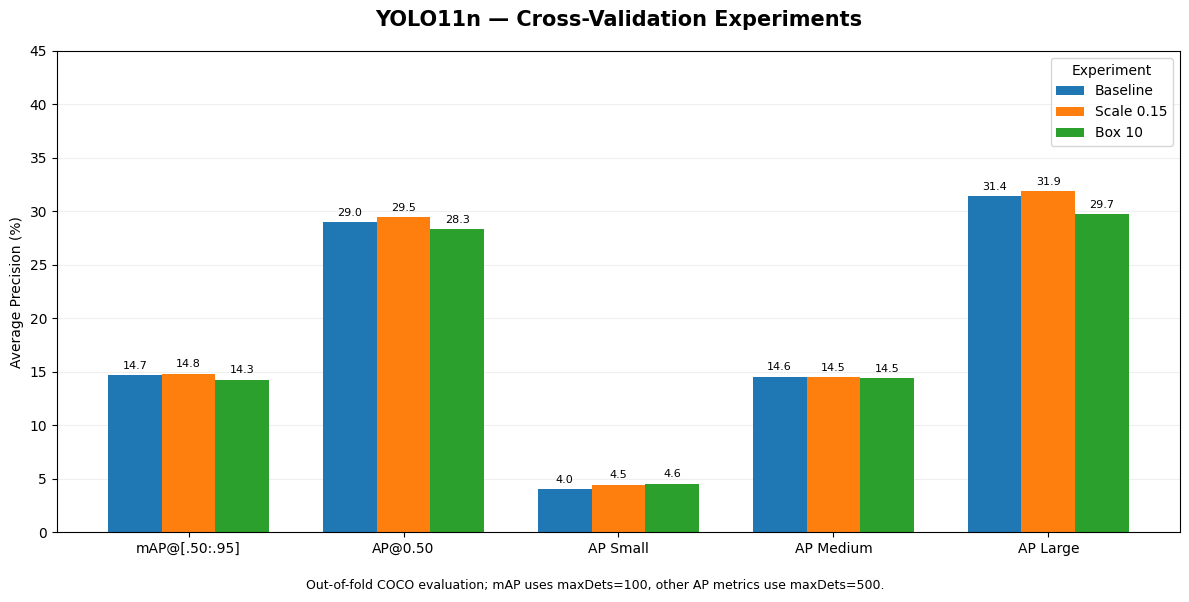

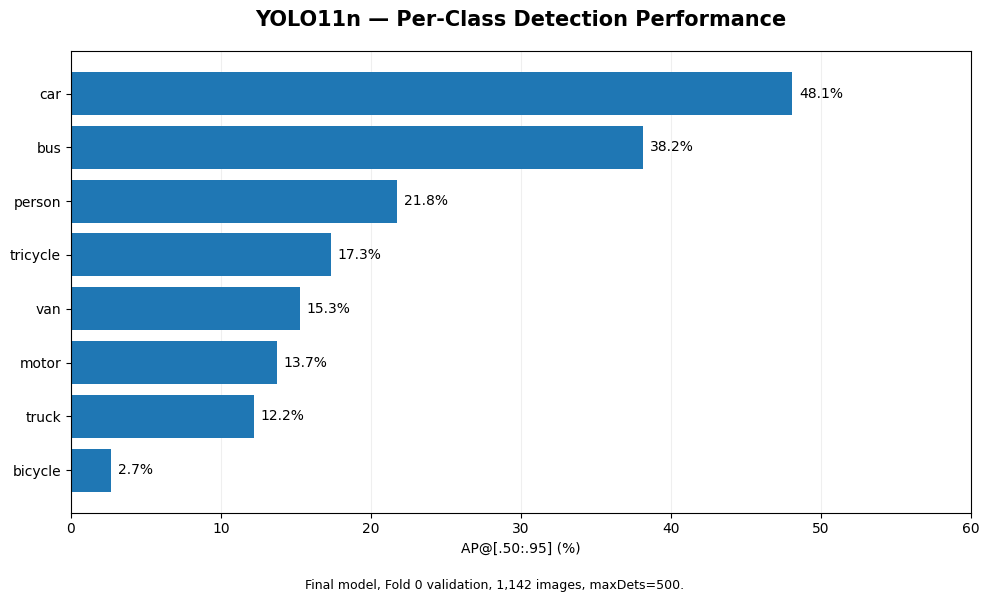


YOLO11n VISUALIZATIONS CREATED
Figures generated: 2
PNG files: 2
PDF files: 2
Saved to: /content/drive_results/MyDrive/hw2_yolo/results_plots

Best CV experiment: Scale 0.15
Best CV mAP: 0.1484


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Output directory
PLOTS_DIR = ROOT / "results_plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# FIGURE 1 — CV Experiments Comparison
# ==========================================

metric_order = [
    "mAP",
    "AP50",
    "AP_small",
    "AP_medium",
    "AP_large"
]

metric_labels = [
    "mAP@[.50:.95]",
    "AP@0.50",
    "AP Small",
    "AP Medium",
    "AP Large"
]

experiments = [
    ("Baseline", "Baseline"),
    ("Scale 0.15", "Scale 0.15"),
    ("Box 10", "Box 10")
]

cv_plot = (
    cv_results
    .set_index("Metric")
    .loc[metric_order]
)

x = np.arange(len(metric_order))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

for i, (column, label) in enumerate(experiments):

    values = cv_plot[column].to_numpy() * 100
    positions = x + (i - 1) * width

    bars = ax.bar(
        positions,
        values,
        width,
        label=label
    )

    ax.bar_label(
        bars,
        fmt="%.1f",
        padding=3,
        fontsize=8
    )

ax.set_title(
    "YOLO11n — Cross-Validation Experiments",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_ylabel("Average Precision (%)")
ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 45)
ax.legend(title="Experiment")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.5, 0.01,
    "Out-of-fold COCO evaluation; "
    "mAP uses maxDets=100, other AP metrics use maxDets=500.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    PLOTS_DIR / "yolo_cv_comparison.png",
    dpi=250,
    bbox_inches="tight"
)
fig.savefig(
    PLOTS_DIR / "yolo_cv_comparison.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==========================================
# FIGURE 2 — Per-Class Detection Performance
# ==========================================

class_plot = (
    per_class_results
    .sort_values("AP50_95", ascending=False)
    .reset_index(drop=True)
)

classes = class_plot["class"].to_numpy()
values = class_plot["AP50_95"].to_numpy() * 100

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    classes,
    values
)

ax.invert_yaxis()

ax.bar_label(
    bars,
    labels=[f"{v:.1f}%" for v in values],
    padding=5,
    fontsize=10
)

ax.set_xlim(0, 60)
ax.set_xlabel("AP@[.50:.95] (%)")

ax.set_title(
    "YOLO11n — Per-Class Detection Performance",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.5, 0.01,
    "Final model, Fold 0 validation, "
    "1,142 images, maxDets=500.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    PLOTS_DIR / "yolo_per_class_ap.png",
    dpi=250,
    bbox_inches="tight"
)
fig.savefig(
    PLOTS_DIR / "yolo_per_class_ap.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==========================================
# SUMMARY
# ==========================================

print("\nYOLO11n VISUALIZATIONS CREATED")
print("=" * 50)
print("Figures generated: 2")
print("PNG files: 2")
print("PDF files: 2")
print("Saved to:", PLOTS_DIR)

best_experiment = cv_plot.loc["mAP", [
    "Baseline", "Scale 0.15", "Box 10"
]].idxmax()

print("\nBest CV experiment:", best_experiment)
print(
    "Best CV mAP:",
    round(cv_plot.loc["mAP", best_experiment], 4)
)